# 08 - Macroeconomic Exploratory Data Analysis

## 1. Introduction and Research Objectives

### 1.1 Objective

The objective of this notebook is to investigate the historical behaviour and statistical characteristics of the UK macroeconomic and financial variables previously acquired for the research project.

The analysis aims to understand their historical evolution, distributions, temporal coverage and relevant data characteristics.

### 1.2 Variables Under Analysis

The analysis covers the following variables:

**Interest Rates**
- Bank of England Bank Rate.
- Sterling Overnight Index Average (SONIA).

**Government Bond Yields**
- UK Government Bond Yield — 2-Year.
- UK Government Bond Yield — 10-Year.

**Inflation**
- UK Consumer Prices Index (CPI).
- UK Core CPI.
- UK Consumer Prices Index including owner occupiers' housing costs (CPIH).

**Economic Growth**
- UK Real Gross Domestic Product (GDP).
- UK GDP Growth.

### 1.3 Research Questions

The analysis will investigate:

1. What is the historical evolution of each macroeconomic variable?
2. What are the main characteristics of their distributions?
3. How do their frequencies and historical coverage differ?
4. What relevant historical patterns can be identified?
5. What data limitations must be considered in subsequent research?

### 1.4 Methodological Principles

- Use previously acquired Raw datasets.
- Preserve original source data.
- Do not apply automatic imputation or remove observations.
- Respect the original frequency and observation dates.
- Distinguish observation dates from publication and availability dates.
- Preserve the data quality and Point-in-Time limitations identified during Phase 3.
- Avoid interpreting historical relationships as evidence of causality.

### 1.5 Scope

This notebook focuses exclusively on the exploratory analysis of individual macroeconomic and financial variables.

Cross-asset relationships and interactions between macroeconomic variables and equity instruments will be examined in Notebook 07.

Forecasting models, trading signals and strategy development are outside the scope of this notebook.

## 2. Interest Rates

### 2.1 Historical Evolution of UK Interest Rates

This section examines the historical evolution of two key UK interest rate indicators:

- Bank of England Bank Rate.
- Sterling Overnight Index Average (SONIA).

Bank Rate represents the central bank's monetary policy rate, while SONIA represents the average interest rate on eligible overnight unsecured sterling transactions.

The analysis aims to identify:

- Long-term monetary policy cycles.
- Periods of interest rate increases and decreases.
- Major changes in the UK interest rate environment.
- Differences between Bank Rate and SONIA.

The analysis uses the previously acquired historical datasets. No modifications will be made to the original Raw data.

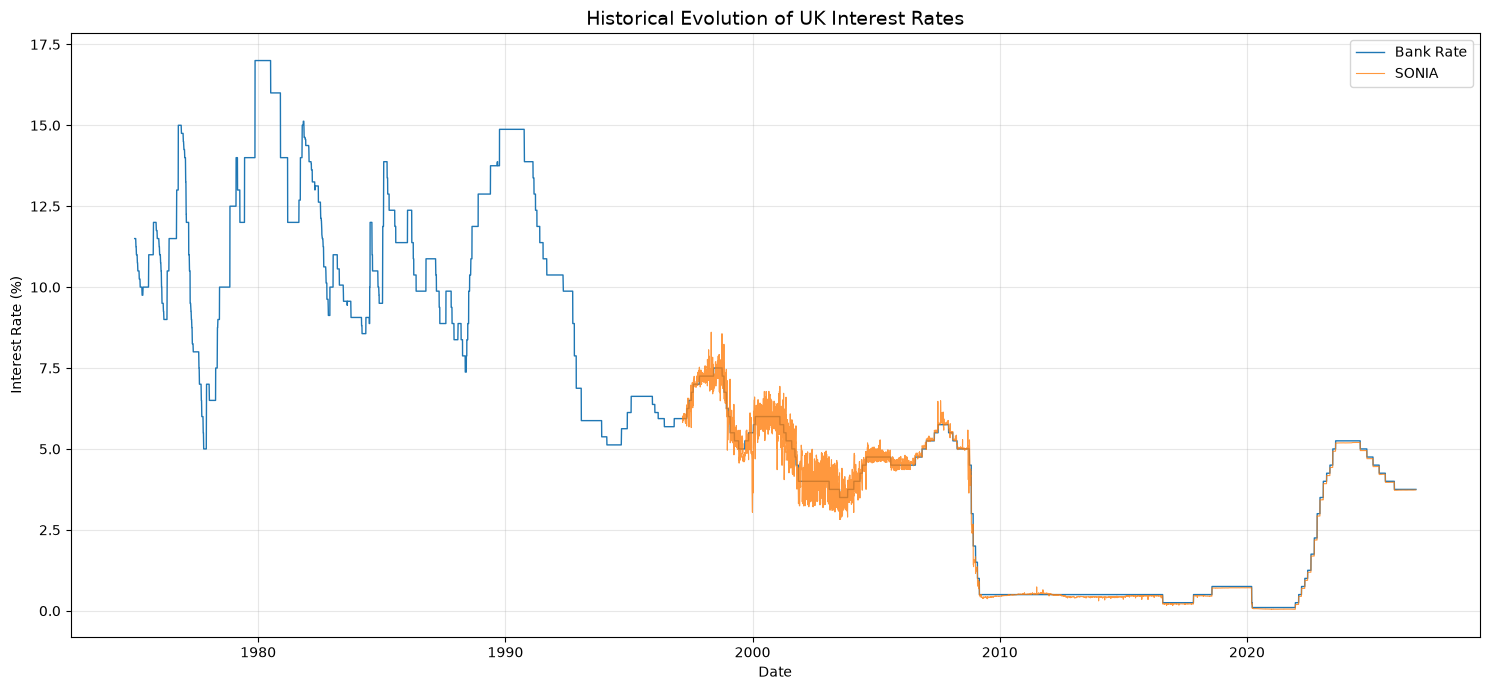

In [104]:
# Import the libraries required for loading and visualising
# the previously acquired UK interest rate datasets.

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt


# Define the project root and the original Raw dataset paths.
PROJECT_ROOT = Path.cwd()

BANK_RATE_PATH = (
    PROJECT_ROOT
    / "data/raw/macro/bank_of_england/uk_interest_rates/bank_rate"
    / "acquisition_20261103T162202Z_855395bd"
    / "original_data.csv"
)

SONIA_PATH = (
    PROJECT_ROOT
    / "data/raw/macro/bank_of_england/uk_interest_rates/sonia"
    / "acquisition_20261103T224853Z_fc90361c"
    / "original_data.csv"
)


# Load the original CSV files without modifying the Raw datasets.
bank_rate_raw = pd.read_csv(
    BANK_RATE_PATH,
    encoding="utf-8-sig"
)

sonia_raw = pd.read_csv(
    SONIA_PATH,
    encoding="utf-8-sig"
)


# Convert the source observation dates into datetime format.
bank_rate_raw["DATE"] = pd.to_datetime(
    bank_rate_raw["DATE"],
    format="%d %b %Y"
)

sonia_raw["DATE"] = pd.to_datetime(
    sonia_raw["DATE"],
    format="%d %b %Y"
)


# Identify the interest rate value columns.
bank_rate_column = next(
    column for column in bank_rate_raw.columns
    if column != "DATE"
)

sonia_column = next(
    column for column in sonia_raw.columns
    if column != "DATE"
)


# Convert the interest rate observations into numeric values.
bank_rate_raw[bank_rate_column] = pd.to_numeric(
    bank_rate_raw[bank_rate_column],
    errors="coerce"
)

sonia_raw[sonia_column] = pd.to_numeric(
    sonia_raw[sonia_column],
    errors="coerce"
)


# Create analytical DataFrames using the observation dates as indexes.
interest_rates = pd.DataFrame({
    "Bank Rate (%)": bank_rate_raw.set_index("DATE")[bank_rate_column],
    "SONIA (%)": sonia_raw.set_index("DATE")[sonia_column]
})


# Plot the historical evolution of both interest rate indicators.
fig, ax = plt.subplots(figsize=(15, 7))

ax.plot(
    interest_rates.index,
    interest_rates["Bank Rate (%)"],
    label="Bank Rate",
    linewidth=1
)

ax.plot(
    interest_rates.index,
    interest_rates["SONIA (%)"],
    label="SONIA",
    linewidth=0.8,
    alpha=0.8
)

ax.set_title(
    "Historical Evolution of UK Interest Rates",
    fontsize=14
)

ax.set_xlabel("Date")
ax.set_ylabel("Interest Rate (%)")

ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

### 2.2 Interest Rate Research Findings

The historical analysis of Bank Rate and SONIA reveals several distinct monetary policy regimes.

**Historical Monetary Policy Regimes**

The historical series can be broadly characterised by:

- Elevated interest rates during the late 1970s and 1980s.
- A general decline throughout much of the 1990s.
- Fluctuating interest rates during the 2000s.
- A prolonged low-interest-rate environment between 2009 and 2021.
- A substantial tightening cycle from 2022, followed by a subsequent reduction.

**Bank Rate and SONIA Behaviour**

Bank Rate and SONIA exhibit broadly similar movements during their overlapping historical periods.

SONIA displays more frequent short-term fluctuations, whereas Bank Rate changes primarily through monetary policy decisions.

**Potential Modelling Implications**

Interest rates may provide economically relevant explanatory information for forecasting UK utility companies.

Their potential relevance includes:

- Corporate financing conditions.
- Debt servicing costs.
- Investment and capital expenditure decisions.
- Changes in the broader economic environment.

These relationships remain research hypotheses and require empirical evaluation during subsequent modelling phases.

Historical monetary policy regimes also suggest that model validation should account for changing economic conditions rather than relying exclusively on random train-test splits.

### 2.3 Descriptive Statistics of Interest Rates

This section summarises the historical statistical characteristics of Bank Rate and SONIA.

The analysis includes:

- Number of valid observations.
- Mean and median.
- Standard deviation.
- Minimum and maximum.
- 25th and 75th percentiles.

These statistics provide a concise overview of the historical interest rate levels and their variability.

The results will help characterise the historical monetary policy environment and identify differences between the two interest rate indicators.

The statistics are descriptive and do not represent forecasts or estimates of future interest rates.

In [105]:
# Calculate descriptive statistics for Bank Rate and SONIA.
# Pandas describe() provides the main statistical measures.

interest_rate_statistics = interest_rates.describe().T

# Rename columns for clarity.
interest_rate_statistics = interest_rate_statistics.rename(
    columns={
        "count": "Observations",
        "mean": "Mean (%)",
        "std": "Standard Deviation (%)",
        "min": "Minimum (%)",
        "25%": "25th Percentile (%)",
        "50%": "Median (%)",
        "75%": "75th Percentile (%)",
        "max": "Maximum (%)"
    }
)

# Display the descriptive statistics.
display(
    interest_rate_statistics.round(4)
)

,Observations,Mean (%),Standard Deviation (%),Minimum (%),25th Percentile (%),Median (%),75th Percentile (%),Maximum (%)
Bank Rate (%),13104.0,6.1103,4.6160,0.1000,0.7500,5.2500,9.8750,17.0000
SONIA (%),7496.0,2.8365,2.3702,0.0394,0.4589,3.3958,4.9296,8.6068


### 2.4 Historical Evolution of UK Government Bond Yields

This section examines the historical evolution of UK Government Bond yields for two maturities:

- 2-Year Government Bond Yield.
- 10-Year Government Bond Yield.

The analysis aims to identify:

- Long-term movements in government bond yields.
- Differences between short-term and long-term interest rates.
- Major changes in the UK government bond market.
- Historical periods of rising and declining yields.

The comparison provides an initial understanding of the UK yield environment and its potential relevance to utility companies.

The analysis uses the previously acquired Bank of England datasets. Original observations and source frequencies are preserved.

/tmp/ipykernel_63064/2922361774.py:76: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  extracted_df["Date"] = pd.to_datetime(


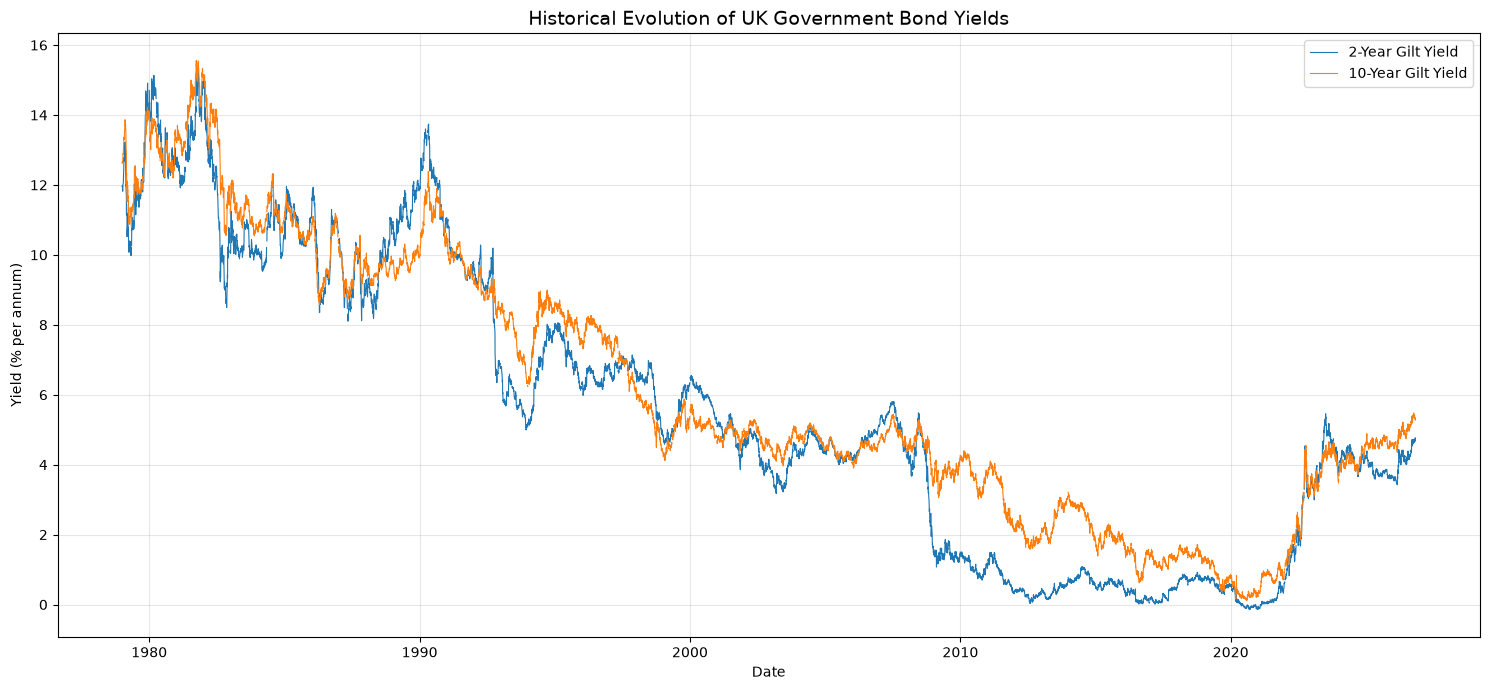

In [106]:
# Load UK Government Bond yield data from the original
# Bank of England acquisition archive.

from io import BytesIO
from zipfile import ZipFile

import pandas as pd
import matplotlib.pyplot as plt


# Define the original Raw archive.
GILT_ARCHIVE_PATH = (
    PROJECT_ROOT
    / "data/raw/macro/bank_of_england/yield_curve_archive"
    / "acquisition_20261105T125522Z_eec59b41"
    / "original_data.zip"
)


# Extract the 2-Year and 10-Year yields from each workbook.
gilt_data = []

with ZipFile(GILT_ARCHIVE_PATH, "r") as archive:

    workbook_files = [
        name for name in archive.namelist()
        if name.endswith(".xlsx")
    ]

    for workbook_name in workbook_files:

        workbook_bytes = BytesIO(
            archive.read(workbook_name)
        )

        excel_file = pd.ExcelFile(workbook_bytes)

        sheet_name = next(
            sheet for sheet in excel_file.sheet_names
            if "spot curve" in sheet.lower()
        )

        raw_df = pd.read_excel(
            excel_file,
            sheet_name=sheet_name,
            header=None
        )

        # Identify the maturity header row.
        header_row = next(
            index for index, value in enumerate(raw_df.iloc[:, 0])
            if str(value).strip().lower() == "years:"
        )

        headers = raw_df.iloc[header_row].tolist()

        # Locate the 2-Year and 10-Year maturity columns.
        maturity_columns = {
            float(value): index
            for index, value in enumerate(headers)
            if pd.notna(value)
            and isinstance(value, (int, float))
        }

        # Extract dates and the two required yield maturities.
        extracted_df = pd.DataFrame({
            "Date": raw_df.iloc[header_row + 1:, 0],
            "Gilt 2-Year (%)": raw_df.iloc[
                header_row + 1:, maturity_columns[2.0]
            ],
            "Gilt 10-Year (%)": raw_df.iloc[
                header_row + 1:, maturity_columns[10.0]
            ]
        })

        extracted_df["Date"] = pd.to_datetime(
            extracted_df["Date"],
            errors="coerce"
        )

        gilt_data.append(extracted_df)


# Combine the historical observations from all workbooks.
gilt_yields = (
    pd.concat(gilt_data, ignore_index=True)
    .dropna(subset=["Date"])
    .sort_values("Date")
    .set_index("Date")
)

gilt_yields = gilt_yields[
    ["Gilt 2-Year (%)", "Gilt 10-Year (%)"]
]


# Visualise the historical evolution of both maturities.
fig, ax = plt.subplots(figsize=(15, 7))

ax.plot(
    gilt_yields.index,
    gilt_yields["Gilt 2-Year (%)"],
    label="2-Year Gilt Yield",
    linewidth=0.8
)

ax.plot(
    gilt_yields.index,
    gilt_yields["Gilt 10-Year (%)"],
    label="10-Year Gilt Yield",
    linewidth=0.8
)

ax.set_title(
    "Historical Evolution of UK Government Bond Yields",
    fontsize=14
)

ax.set_xlabel("Date")
ax.set_ylabel("Yield (% per annum)")

ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

### 2.5 Descriptive Statistics of Government Bond Yields

This section summarises the historical statistical characteristics of the UK 2-Year and 10-Year Government Bond yields.

The analysis includes the number of observations, mean, median, standard deviation, minimum, maximum and quartiles.

These statistics provide a concise comparison of short-term and long-term government borrowing costs.

The results will support the identification of relevant interest rate characteristics for subsequent forecasting research.

In [107]:
# Convert government bond yield columns to numeric values.
# The original Raw datasets remain unchanged.

gilt_yields = gilt_yields.apply(
    pd.to_numeric,
    errors="coerce"
)

# Calculate descriptive statistics.
gilt_yield_statistics = gilt_yields.describe().T

# Display the results.
display(
    gilt_yield_statistics.round(4)
)

,count,mean,std,min,25%,50%,75%,max
Gilt 2-Year (%),12090.0,5.5408,4.1133,-0.1420,1.2970,4.9007,9.2650,15.4901
Gilt 10-Year (%),12090.0,6.0849,3.7662,0.1114,3.5002,4.9009,9.3873,15.5571


### 2.6 Government Bond Yield Findings

The historical analysis identifies a long-term decline in UK Government Bond yields, followed by a substantial increase from 2022.

The descriptive statistics reveal that:

- The 10-Year Gilt exhibits a higher historical mean yield (6.0849%) than the 2-Year Gilt (5.5408%).
- The 2-Year Gilt exhibits higher historical standard deviation (4.1133%) than the 10-Year Gilt (3.7662%).
- Both maturities have almost identical median yields.

These findings indicate differences in the historical behaviour of short-term and long-term government bond yields.

### Potential Modelling Implications

Both maturities may provide relevant information about the UK interest rate environment.

Their potential usefulness as forecasting features will be evaluated during subsequent modelling research.

The historical statistics should not be interpreted as estimates of future interest rates.

## 3. Inflation

### 3.1 Historical Evolution of UK Inflation Indicators

This section examines three UK inflation indicators:

- Consumer Prices Index (CPI).
- Core CPI.
- Consumer Prices Index including owner occupiers' housing costs (CPIH).

The analysis aims to understand their historical evolution and identify major changes in the UK inflation environment.

Particular attention will be given to:

- Long-term inflation trends.
- Periods of increasing and declining inflation.
- Differences between headline and core inflation.
- Major inflationary episodes.

These indicators may provide economically relevant information for understanding the operating and financial environment of UK utility companies.

The analysis uses the previously acquired datasets. Original observations and source frequencies will be preserved.

In [108]:
# Load the previously acquired UK inflation datasets.
# The original Raw files remain unchanged.

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Locate the existing ONS inflation acquisition directories.
ONS_RAW_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "macro"
    / "ons"
)

for path in ONS_RAW_PATH.rglob("*"):
    if path.is_file():
        print(path.relative_to(PROJECT_ROOT))

data/raw/macro/ons/gdp/acquisition_20261105T132956Z_60b29116/original_data.csv
data/raw/macro/ons/gdp/acquisition_20261105T132956Z_60b29116/manifest.json
data/raw/macro/ons/inflation/acquisition_20261105T132954Z_b4ce351c/original_data.csv
data/raw/macro/ons/inflation/acquisition_20261105T132954Z_b4ce351c/manifest.json


In [109]:
# Load the previously acquired UK inflation dataset.
# The original Raw file remains unchanged.

INFLATION_PATH = (
    PROJECT_ROOT
    / "data/raw/macro/ons/inflation"
    / "acquisition_20261105T132954Z_b4ce351c"
    / "original_data.csv"
)

inflation_raw = pd.read_csv(INFLATION_PATH)

# Display the column names and first observations
# to identify the three inflation indicators.
print("Available columns:")
print(inflation_raw.columns.tolist())

display(inflation_raw.head(5))

/tmp/ipykernel_63064/1892661766.py:11: DtypeWarning: Columns (1: CPI wts: Non-energy industrial goods GOODS, 2: CPI wts: Durables GOODS, 3: CPI wts: Semi-durables GOODS, 4: CPI wts: Non-durables GOODS, 5: CPI wts: Non-seasonal food GOODS, 6: CPI wts: Food, alcoholic beverages & tobacco GOODS, 7: CPI wts: Processed food & non-alcoholic beverages GOODS, 8: CPI wts: Unprocessed food GOODS, 9: CPI wts: Seasonal food GOODS, 10: CPI wts: Industrial goods GOODS, 11: CPI wts: Energy GOODS, 12: CPI wts: Electricity, gas & misc. energy GOODS, 13: CPI wts: CPI excluding tobacco SPECIAL AGGREGATES, 14: CPI wts: Clothing & footwear goods GOODS, 15: CPI wts: Housing goods GOODS, 16: CPI wts: Household goods GOODS, 17: CPI wts: Water supply; materials for maintenance & repair GOODS, 18: CPI wts: Medical goods GOODS, 19: CPI wts: Vehicles, spare parts & accessories GOODS, 20: CPI wts: Recreational goods GOODS, 21: CPI wts: Audio-visual goods GOODS, 22: CPI wts: Other recreational goods GOODS, 23: CPI 

Available columns:
['Title', 'CPI wts: Non-energy industrial goods GOODS', 'CPI wts: Durables GOODS', 'CPI wts: Semi-durables GOODS', 'CPI wts: Non-durables GOODS', 'CPI wts: Non-seasonal food GOODS', 'CPI wts: Food, alcoholic beverages & tobacco GOODS', 'CPI wts: Processed food & non-alcoholic beverages GOODS', 'CPI wts: Unprocessed food GOODS', 'CPI wts: Seasonal food GOODS', 'CPI wts: Industrial goods GOODS', 'CPI wts: Energy GOODS', 'CPI wts: Electricity, gas & misc. energy GOODS', 'CPI wts: CPI excluding tobacco SPECIAL AGGREGATES', 'CPI wts: Clothing & footwear goods GOODS', 'CPI wts: Housing goods GOODS', 'CPI wts: Household goods GOODS', 'CPI wts: Water supply; materials for maintenance & repair GOODS', 'CPI wts: Medical goods GOODS', 'CPI wts: Vehicles, spare parts & accessories GOODS', 'CPI wts: Recreational goods GOODS', 'CPI wts: Audio-visual goods GOODS', 'CPI wts: Other recreational goods GOODS', 'CPI wts: Miscellaneous goods GOODS', 'CPI wts: Housing services SERVICES', 

,Title,CPI wts: Non-energy industrial goods GOODS,CPI wts: Durables GOODS,CPI wts: Semi-durables GOODS,CPI wts: Non-durables GOODS,CPI wts: Non-seasonal food GOODS,"CPI wts: Food, alcoholic beverages & tobacco GOODS",CPI wts: Processed food & non-alcoholic beverages GOODS,CPI wts: Unprocessed food GOODS,CPI wts: Seasonal food GOODS,...,CPI: % points change over previous month (12 month rate): Furniture & hhold good,CPI: % points change over previous month (12 month rate): Health,CPI: % points change over previous month (12 month rate): Transport,CPI: % points change over previous month (12 month rate): Communication,CPI: % points change over previous month (12 month rate): Recreation & culture,CPI: % points change over previous month (12 month rate): Education,CPI: % points change over previous month (12 month rate): Restaurants & hotels,CPI: % points change over previous month (12 month rate): Misc goods & services,Internal purchasing power of the pound (based on RPI): 2000 = 100,"RPI: Ave price - Salmon fillets, per Kg"
0,CDID,A9ER,A9ES,A9ET,A9EU,A9EV,A9EW,A9EX,A9EY,A9EZ,...,WUNQ,WUNZ,WUOA,WUOO,WUOP,WUOU,WUOV,WUOW,ZMHO,ZPTX
1,PreUnit,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Unit,Parts per 1000,Parts per 1000,Parts per 1000,Parts per 1000,Parts per 1000,Parts per 1000,Parts per 1000,Parts per 1000,Parts per 1000,...,%,%,%,%,%,%,%,%,Pence,Pence
3,Release Date,21-10-2026,21-10-2026,21-10-2026,21-10-2026,21-10-2026,21-10-2026,21-10-2026,21-10-2026,21-10-2026,...,21-10-2026,21-10-2026,21-10-2026,21-10-2026,21-10-2026,21-10-2026,21-10-2026,21-10-2026,21-10-2026,21-10-2026
4,Next release,18 November 2026,18 November 2026,18 November 2026,18 November 2026,18 November 2026,18 November 2026,18 November 2026,18 November 2026,18 November 2026,...,18 November 2026,18 November 2026,18 November 2026,18 November 2026,18 November 2026,18 November 2026,18 November 2026,18 November 2026,18 November 2026,18 November 2026


In [110]:
# Identify the ONS time series using their official CDID codes.
# The original CSV contains metadata rows before the historical observations.

INFLATION_SERIES = {
    "CPI": "D7G7",
    "Core CPI": "DKO8",
    "CPIH": "L55O",
}

# Locate the columns corresponding to the required indicators.
inflation_columns = {}

for indicator, cdid in INFLATION_SERIES.items():

    matching_columns = inflation_raw.columns[
        inflation_raw.iloc[0].astype(str) == cdid
    ]

    if len(matching_columns) != 1:
        raise ValueError(
            f"Expected one column for {indicator} ({cdid}), "
            f"but found {len(matching_columns)}."
        )

    inflation_columns[indicator] = matching_columns[0]

# Display the selected series and their metadata.
for indicator, column in inflation_columns.items():

    print(f"\n{indicator}")
    print(f"Column: {column}")
    print(f"CDID: {inflation_raw.loc[0, column]}")
    print(f"Unit: {inflation_raw.loc[2, column]}")
    print(f"Release date: {inflation_raw.loc[3, column]}")

    print("Initial observations:")
    display(inflation_raw[[column]].iloc[5:10])


CPI
Column: CPI ANNUAL RATE 00: ALL ITEMS 2015=100
CDID: D7G7
Unit: %
Release date: 21-10-2026
Initial observations:


,CPI ANNUAL RATE 00: ALL ITEMS 2015=100
5,NaN
6,NaN
7,NaN
8,NaN
9,NaN



Core CPI
Column: CPI 12mth: Excluding Energy, food, alcoholic beverages & tobacco 2015=100
CDID: DKO8
Unit: %
Release date: 21-10-2026
Initial observations:


,"CPI 12mth: Excluding Energy, food, alcoholic beverages & tobacco 2015=100"
5,NaN
6,NaN
7,NaN
8,NaN
9,NaN



CPIH
Column: CPIH ANNUAL RATE 00: ALL ITEMS 2015=100
CDID: L55O
Unit: %
Release date: 21-10-2026
Initial observations:


,CPIH ANNUAL RATE 00: ALL ITEMS 2015=100
5,NaN
6,NaN
7,NaN
8,NaN
9,NaN


In [111]:
# Examine the historical coverage of the three selected ONS inflation series.
# The original metadata rows are excluded from the observation count.

inflation_coverage = {}

for indicator, column in inflation_columns.items():

    # Extract the selected series without modifying the original dataset.
    series = inflation_raw[column].iloc[5:]

    # Convert values to numeric for statistical inspection.
    numeric_series = pd.to_numeric(
        series,
        errors="coerce"
    )

    # Identify the first and last valid observations.
    valid_values = numeric_series.dropna()

    inflation_coverage[indicator] = {
        "CDID": inflation_raw.loc[0, column],
        "Unit": inflation_raw.loc[2, column],
        "Total Rows": len(numeric_series),
        "Valid Observations": valid_values.count(),
        "Missing Observations": numeric_series.isna().sum(),
        "First Valid Index": (
            valid_values.index.min()
            if not valid_values.empty else None
        ),
        "Last Valid Index": (
            valid_values.index.max()
            if not valid_values.empty else None
        ),
        "Minimum Value": valid_values.min(),
        "Maximum Value": valid_values.max(),
    }

inflation_coverage_df = pd.DataFrame(
    inflation_coverage
).T

display(inflation_coverage_df)

,CDID,Unit,Total Rows,Valid Observations,Missing Observations,First Valid Index,Last Valid Index,Minimum Value,Maximum Value
CPI,D7G7,%,1493,641,852,195,1497,-0.1,11.1
Core CPI,DKO8,%,1493,641,852,195,1497,-0.1,8.2
CPIH,L55O,%,1493,641,852,195,1497,0.2,9.6


In [112]:
# Inspect the first column to identify how historical periods are represented.
# The selected CPI series are displayed alongside their corresponding period labels.

first_valid_index = 195
last_valid_index = 1497

# Display the rows immediately before and after the first valid observations.
print("First valid observations and surrounding rows:")

display(
    inflation_raw.loc[
        first_valid_index - 5:first_valid_index + 5,
        ["Title"] + list(inflation_columns.values())
    ]
)

# Display the most recent observations.
print("\nLast observations:")

display(
    inflation_raw.loc[
        last_valid_index - 9:last_valid_index,
        ["Title"] + list(inflation_columns.values())
    ]
)

# Inspect the data types of the relevant columns.
print("\nColumn data types:")

display(
    inflation_raw[
        ["Title"] + list(inflation_columns.values())
    ].dtypes
)

First valid observations and surrounding rows:


,Title,CPI ANNUAL RATE 00: ALL ITEMS 2015=100,"CPI 12mth: Excluding Energy, food, alcoholic beverages & tobacco 2015=100",CPIH ANNUAL RATE 00: ALL ITEMS 2015=100
190,1984,NaN,NaN,NaN
191,1985,NaN,NaN,NaN
192,1986,NaN,NaN,NaN
193,1987,NaN,NaN,NaN
194,1988,NaN,NaN,NaN
195,1989,5.2,5.1,5.7
196,1990,7.0,6.3,8.0
197,1991,7.5,7.6,7.5
198,1992,4.2,4.5,4.6
199,1993,2.5,2.4,2.6



Last observations:


,Title,CPI ANNUAL RATE 00: ALL ITEMS 2015=100,"CPI 12mth: Excluding Energy, food, alcoholic beverages & tobacco 2015=100",CPIH ANNUAL RATE 00: ALL ITEMS 2015=100
1488,2025 DEC,3.4,3.2,3.6
1489,2026 JAN,3.0,3.1,3.2
1490,2026 FEB,3.0,3.2,3.2
1491,2026 MAR,3.3,3.1,3.4
1492,2026 APR,2.8,2.5,3.0
1493,2026 MAY,2.8,2.6,3.0
1494,2026 JUN,2.6,2.6,2.8
1495,2026 JUL,2.9,2.6,3.1
1496,2026 AUG,3.1,2.6,3.3
1497,2026 SEP,3.5,2.8,3.6



Column data types:


Title                                                                           str
CPI ANNUAL RATE 00: ALL ITEMS 2015=100                                       object
CPI 12mth: Excluding Energy, food, alcoholic beverages & tobacco 2015=100    object
CPIH ANNUAL RATE 00: ALL ITEMS 2015=100                                      object
dtype: object

In [113]:
# Inspect the period labels around the transition from annual to monthly observations.
# This helps establish the original temporal structure without modifying the Raw data.

print("Period labels around the beginning of the valid observations:")

display(
    inflation_raw.loc[
        195:225,
        ["Title"] + list(inflation_columns.values())
    ]
)

print("\nPeriod labels around the most recent observations:")

display(
    inflation_raw.loc[
        1470:1497,
        ["Title"] + list(inflation_columns.values())
    ]
)

Period labels around the beginning of the valid observations:


,Title,CPI ANNUAL RATE 00: ALL ITEMS 2015=100,"CPI 12mth: Excluding Energy, food, alcoholic beverages & tobacco 2015=100",CPIH ANNUAL RATE 00: ALL ITEMS 2015=100
195,1989,5.2,5.1,5.7
196,1990,7.0,6.3,8.0
197,1991,7.5,7.6,7.5
198,1992,4.2,4.5,4.6
199,1993,2.5,2.4,2.6
200,1994,2.0,1.7,2.2
201,1995,2.6,2.0,2.7
202,1996,2.4,2.0,2.9
203,1997,1.8,1.9,2.2
204,1998,1.6,1.5,1.8



Period labels around the most recent observations:


,Title,CPI ANNUAL RATE 00: ALL ITEMS 2015=100,"CPI 12mth: Excluding Energy, food, alcoholic beverages & tobacco 2015=100",CPIH ANNUAL RATE 00: ALL ITEMS 2015=100
1470,2024 JUN,2.0,3.5,2.8
1471,2024 JUL,2.2,3.3,3.1
1472,2024 AUG,2.2,3.6,3.1
1473,2024 SEP,1.7,3.2,2.6
1474,2024 OCT,2.3,3.3,3.2
1475,2024 NOV,2.6,3.5,3.5
1476,2024 DEC,2.5,3.2,3.5
1477,2025 JAN,3.0,3.7,3.9
1478,2025 FEB,2.8,3.5,3.7
1479,2025 MAR,2.6,3.4,3.4


In [114]:
# Inspect all period labels between 2018 and 2024.
# This identifies the transition between annual and monthly observations
# and helps detect possible gaps or overlapping periods.

transition_mask = inflation_raw["Title"].astype(str).str.startswith(
    ("2018", "2019", "2020", "2021", "2022", "2023", "2024")
)

transition_data = inflation_raw.loc[
    transition_mask,
    ["Title"] + list(inflation_columns.values())
].copy()

display(transition_data)

print("\nNumber of observations in the transition period:")
print(len(transition_data))

,Title,CPI ANNUAL RATE 00: ALL ITEMS 2015=100,"CPI 12mth: Excluding Energy, food, alcoholic beverages & tobacco 2015=100",CPIH ANNUAL RATE 00: ALL ITEMS 2015=100
224,2018,2.5,2.1,2.3
225,2019,1.8,1.7,1.7
226,2020,0.9,1.4,1.0
227,2021,2.6,2.4,2.5
228,2022,9.1,5.9,7.9
...,...,...,...,...
1472,2024 AUG,2.2,3.6,3.1
1473,2024 SEP,1.7,3.2,2.6
1474,2024 OCT,2.3,3.3,3.2
1475,2024 NOV,2.6,3.5,3.5



Number of observations in the transition period:
119


In [115]:
# Separate monthly and annual observations for the selected inflation indicators.
# The original ONS Raw dataset remains unchanged.

# Identify monthly observations using the YYYY MON period-label format.
monthly_mask = (
    inflation_raw["Title"]
    .astype(str)
    .str.match(r"^\d{4}\s+[A-Z]{3}$")
)

# Identify annual observations using the YYYY format.
annual_mask = (
    inflation_raw["Title"]
    .astype(str)
    .str.match(r"^\d{4}$")
)

selected_columns = list(inflation_columns.values())

# Create independent analytical copies of the original observations.
inflation_monthly_raw = inflation_raw.loc[
    monthly_mask,
    ["Title"] + selected_columns
].copy()

inflation_annual_raw = inflation_raw.loc[
    annual_mask,
    ["Title"] + selected_columns
].copy()

# Report the number of observations in each frequency.
print("Monthly observations:", len(inflation_monthly_raw))
print("Annual observations:", len(inflation_annual_raw))

print("\nMonthly period labels:")
display(inflation_monthly_raw["Title"].head())
display(inflation_monthly_raw["Title"].tail())

print("\nAnnual period labels:")
display(inflation_annual_raw["Title"].head())
display(inflation_annual_raw["Title"].tail())

Monthly observations: 952
Annual observations: 227

Monthly period labels:


546    1947 JUN
547    1947 JUL
548    1947 AUG
549    1947 SEP
550    1947 OCT
Name: Title, dtype: str

1493    2026 MAY
1494    2026 JUN
1495    2026 JUL
1496    2026 AUG
1497    2026 SEP
Name: Title, dtype: str


Annual period labels:


6     1800
7     1801
8     1802
9     1803
10    1804
Name: Title, dtype: str

228    2022
229    2023
230    2024
231    2025
232    2026
Name: Title, dtype: str

In [116]:
# Assess the actual data coverage of each selected inflation indicator.
# Period labels are separated by frequency, and missing values are excluded
# only from the observation counts. The original Raw dataset is unchanged.

frequency_coverage = {}

for indicator, column in inflation_columns.items():

    monthly_values = pd.to_numeric(
        inflation_monthly_raw[column],
        errors="coerce"
    )

    annual_values = pd.to_numeric(
        inflation_annual_raw[column],
        errors="coerce"
    )

    frequency_coverage[indicator] = {
        "Monthly Valid Observations": monthly_values.notna().sum(),
        "Monthly Missing Observations": monthly_values.isna().sum(),
        "Annual Valid Observations": annual_values.notna().sum(),
        "Annual Missing Observations": annual_values.isna().sum(),
    }

frequency_coverage_df = pd.DataFrame(
    frequency_coverage
).T

display(frequency_coverage_df)

,Monthly Valid Observations,Monthly Missing Observations,Annual Valid Observations,Annual Missing Observations
CPI,453,499,37,190
Core CPI,453,499,37,190
CPIH,453,499,37,190


In [117]:
# Validate the temporal coverage and continuity of the monthly inflation series.
# Only valid observations are considered; the original ONS Raw dataset remains unchanged.

monthly_temporal_coverage = {}

for indicator, column in inflation_columns.items():

    # Convert the selected indicator values to numeric.
    monthly_values = pd.to_numeric(
        inflation_monthly_raw[column],
        errors="coerce"
    )

    # Retain only observations with valid values.
    valid_mask = monthly_values.notna()

    valid_periods = inflation_monthly_raw.loc[
        valid_mask,
        "Title"
    ]

    # Convert the original monthly labels into datetime values.
    monthly_dates = pd.to_datetime(
        valid_periods,
        format="%Y %b"
    )

    # Generate the complete monthly calendar between the first and last observations.
    expected_months = pd.date_range(
        start=monthly_dates.min(),
        end=monthly_dates.max(),
        freq="MS"
    )

    # Identify any missing months within the observed period.
    missing_months = expected_months.difference(
        monthly_dates
    )

    monthly_temporal_coverage[indicator] = {
        "Valid Observations": len(monthly_dates),
        "First Valid Month": monthly_dates.min(),
        "Last Valid Month": monthly_dates.max(),
        "Expected Monthly Observations": len(expected_months),
        "Missing Months Within Coverage": len(missing_months),
    }

    print(f"\n{indicator} — Missing months:")

    if len(missing_months) == 0:
        print("No missing months detected.")
    else:
        display(missing_months)

monthly_temporal_coverage_df = pd.DataFrame(
    monthly_temporal_coverage
).T

print("\nMonthly temporal coverage summary:")

display(monthly_temporal_coverage_df)


CPI — Missing months:
No missing months detected.

Core CPI — Missing months:
No missing months detected.

CPIH — Missing months:
No missing months detected.

Monthly temporal coverage summary:


,Valid Observations,First Valid Month,Last Valid Month,Expected Monthly Observations,Missing Months Within Coverage
CPI,453,1989-01-01 00:00:00,2026-09-01 00:00:00,453,0
Core CPI,453,1989-01-01 00:00:00,2026-09-01 00:00:00,453,0
CPIH,453,1989-01-01 00:00:00,2026-09-01 00:00:00,453,0


In [118]:
# Build the monthly analytical dataset using only valid observations.
# The original ONS Raw dataset remains unchanged.
# All three indicators must have valid values for a month to be retained.

inflation_monthly_df = pd.DataFrame(
    index=pd.to_datetime(
        inflation_monthly_raw["Title"],
        format="%Y %b"
    )
)

# Extract the selected inflation indicators as numeric values.
for indicator, column in inflation_columns.items():

    inflation_monthly_df[indicator] = pd.to_numeric(
        inflation_monthly_raw[column].values,
        errors="coerce"
    )

# Retain only months with valid observations across all indicators.
inflation_monthly_df = inflation_monthly_df.dropna(
    how="any"
)

# Name and sort the monthly index.
inflation_monthly_df.index.name = "Date"

inflation_monthly_df = inflation_monthly_df.sort_index()

# Validate the corrected analytical dataset.
print("Monthly inflation dataset created successfully.")

print("\nDataset shape:")
print(inflation_monthly_df.shape)

print("\nFirst observations:")
display(inflation_monthly_df.head())

print("\nLast observations:")
display(inflation_monthly_df.tail())

print("\nMissing values:")
display(inflation_monthly_df.isna().sum())

print("\nDuplicate dates:")
print(inflation_monthly_df.index.duplicated().sum())

print("\nDate range:")
print(
    inflation_monthly_df.index.min(),
    "to",
    inflation_monthly_df.index.max()
)

Monthly inflation dataset created successfully.

Dataset shape:
(453, 3)

First observations:


,CPI,Core CPI,CPIH
Date,,,
1989-01-01,4.9,5.3,5.7
1989-02-01,5.0,5.3,5.8
1989-03-01,5.0,5.2,5.9
1989-04-01,5.3,5.3,5.6
1989-05-01,5.3,5.2,5.9



Last observations:


,CPI,Core CPI,CPIH
Date,,,
2026-05-01,2.8,2.6,3.0
2026-06-01,2.6,2.6,2.8
2026-07-01,2.9,2.6,3.1
2026-08-01,3.1,2.6,3.3
2026-09-01,3.5,2.8,3.6



Missing values:


CPI         0
Core CPI    0
CPIH        0
dtype: int64


Duplicate dates:
0

Date range:
1989-01-01 00:00:00 to 2026-09-01 00:00:00


### Descriptive Statistics of Inflation

This section examines the historical distribution of the three selected UK inflation indicators: CPI, Core CPI and CPIH.

Descriptive statistics are calculated to assess their central tendency, dispersion, range and distributional characteristics.

The analysis uses the monthly inflation rates expressed as percentages, covering January 1989 to September 2026.

The following measures are considered:

- Mean and median to assess central tendency.
- Standard deviation to measure historical dispersion.
- Minimum and maximum to identify the observed range.
- Quartiles to examine the distribution of observations.
- Skewness to assess distributional asymmetry.
- Excess kurtosis to assess the weight of distribution tails relative to a normal distribution.

These statistics describe historical inflation behaviour. They do not imply predictive relationships or establish causal effects.

In [119]:
# Calculate descriptive statistics for the monthly inflation indicators.
# All statistics are based on the validated monthly analytical dataset.

inflation_statistics_df = inflation_monthly_df.describe().T

# Add distributional measures.
inflation_statistics_df["Skewness"] = (
    inflation_monthly_df.skew()
)

inflation_statistics_df["Excess Kurtosis"] = (
    inflation_monthly_df.kurt()
)

# Rename columns for analytical clarity.
inflation_statistics_df = inflation_statistics_df.rename(
    columns={
        "count": "Observations",
        "mean": "Mean (%)",
        "std": "Standard Deviation (%)",
        "min": "Minimum (%)",
        "25%": "25th Percentile (%)",
        "50%": "Median (%)",
        "75%": "75th Percentile (%)",
        "max": "Maximum (%)",
    }
)

# Display the descriptive statistics.
display(
    inflation_statistics_df.round(4)
)

,Observations,Mean (%),Standard Deviation (%),Minimum (%),25th Percentile (%),Median (%),75th Percentile (%),Maximum (%),Skewness,Excess Kurtosis
CPI,453.0,2.8391,2.1239,-0.1,1.5,2.3,3.2,11.1,1.6646,2.7566
Core CPI,453.0,2.5071,1.7584,-0.1,1.4,1.9,3.0,8.2,1.4567,1.4503
CPIH,453.0,2.9091,1.9926,0.2,1.7,2.4,3.2,9.6,1.6134,2.1627


### Interpretation of Descriptive Statistics

The descriptive statistics reveal several differences between the three UK inflation indicators.

CPIH presents the highest historical mean (2.91%), followed by CPI (2.84%) and Core CPI (2.51%). The median values are lower than the corresponding means across all three indicators, suggesting that periods of elevated inflation have influenced their historical averages.

CPI exhibits the highest standard deviation (2.12 percentage points), while Core CPI presents the lowest (1.76 percentage points). This indicates greater historical dispersion in the headline CPI series relative to the core measure.

The maximum observed inflation rate is 11.1% for CPI, compared with 9.6% for CPIH and 8.2% for Core CPI. The minimum values range from -0.1% for CPI and Core CPI to 0.2% for CPIH.

All three distributions exhibit positive skewness and positive excess kurtosis. This indicates right-skewed distributions with heavier tails than a normal distribution. CPI displays the strongest asymmetry and highest excess kurtosis among the selected indicators.

These findings describe the historical distributions over the sample period. They do not establish causal relationships or imply future inflation behaviour.

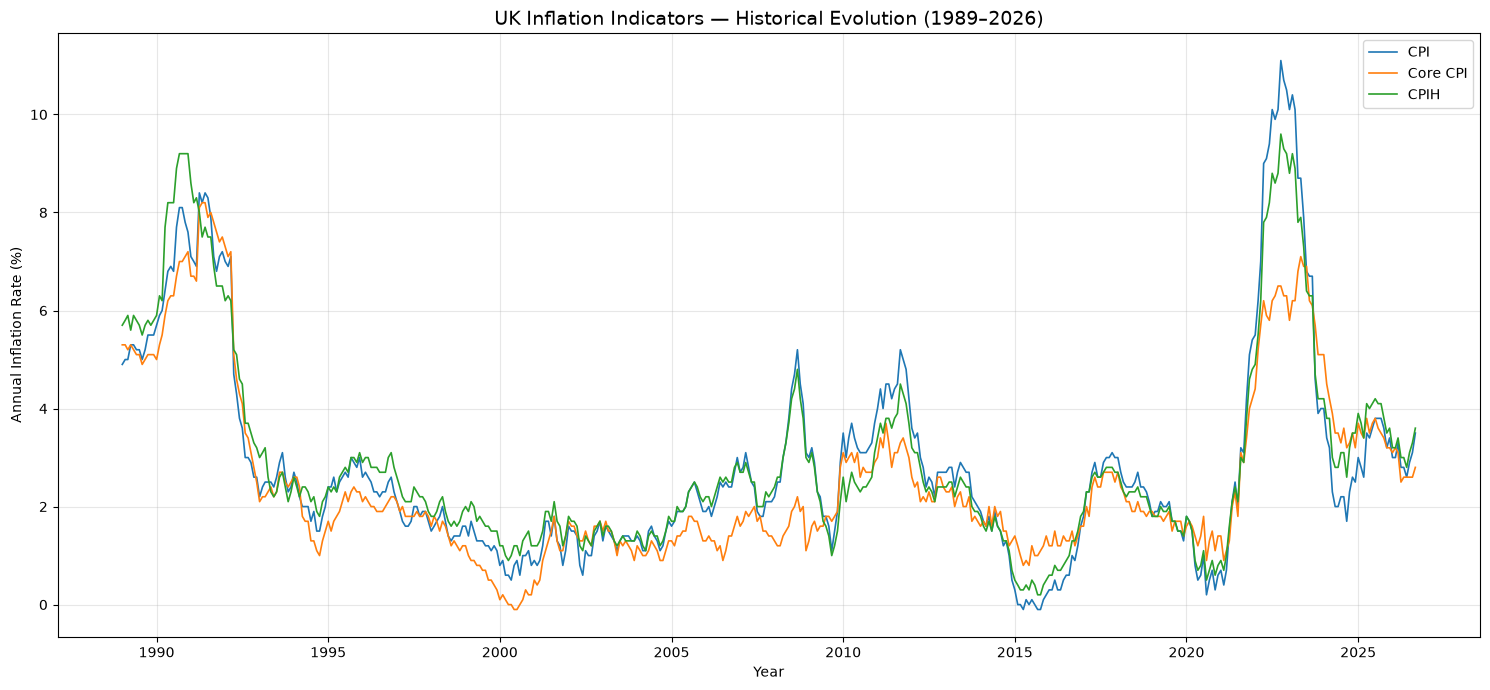

In [120]:
# Plot the historical evolution of the three monthly UK inflation indicators.
# Each series is displayed on the same chart to facilitate comparison.
# Values represent annual inflation rates expressed as percentages.

plt.figure(figsize=(15, 7))

for indicator in inflation_monthly_df.columns:

    plt.plot(
        inflation_monthly_df.index,
        inflation_monthly_df[indicator],
        label=indicator,
        linewidth=1.2
    )

plt.title(
    "UK Inflation Indicators — Historical Evolution (1989–2026)",
    fontsize=14
)

plt.xlabel("Year")
plt.ylabel("Annual Inflation Rate (%)")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Interpretation of Historical Inflation Evolution

The historical inflation series reveal several distinct periods of inflationary acceleration and disinflation between January 1989 and September 2026.

**1989–1992 — Elevated inflation and disinflation**

All three indicators initially display relatively high inflation rates, followed by a substantial decline. CPIH remains above the other measures during parts of this period.

**1993–2007 — Relatively moderate inflation**

Inflation remains predominantly within a relatively narrow range, generally between 1% and 3%, with occasional fluctuations.

**2008–2012 — Increased inflation variability**

The indicators display pronounced movements, including an inflationary increase around 2008, a subsequent decline and another period of elevated inflation between 2010 and 2012.

**2013–2020 — Disinflation**

Inflation generally declines, reaching particularly low levels around 2015–2016. CPI briefly records negative annual inflation rates.

**2021–2023 — Strong inflationary acceleration**

All three indicators increase substantially. CPI reaches approximately 11.1%, CPIH approximately 9.6% and Core CPI approximately 8.2% during the sample period.

**2024–September 2026 — Lower inflation with renewed fluctuations**

Inflation declines from the peaks observed in 2022–2023. However, the three indicators continue to exhibit fluctuations and periods of divergence.

Overall, the three indicators display broadly similar long-term movements, although their magnitudes and distributional characteristics differ.

These observations are descriptive. No causal interpretation is established at this stage.

### Comparing Inflation Indicators

This section examines the differences between the three selected UK inflation indicators.

The analysis focuses on three pairwise comparisons:

- CPI minus Core CPI.
- CPIH minus CPI.
- CPIH minus Core CPI.

Differences are calculated in percentage points rather than relative percentages.

The objective is to examine how headline inflation, core inflation and CPIH have diverged over time.

Positive values indicate that the first indicator is higher than the second, while negative values indicate the opposite.

This analysis is descriptive and does not establish causal relationships or predictive value.

In [121]:
# Calculate pairwise differences between the monthly inflation indicators.
# All differences are expressed in percentage points.
# The validated source dataset remains unchanged.

inflation_spreads_df = pd.DataFrame(index=inflation_monthly_df.index)

# Difference between headline CPI and Core CPI.
inflation_spreads_df["CPI - Core CPI"] = (
    inflation_monthly_df["CPI"]
    - inflation_monthly_df["Core CPI"]
)

# Difference between CPIH and headline CPI.
inflation_spreads_df["CPIH - CPI"] = (
    inflation_monthly_df["CPIH"]
    - inflation_monthly_df["CPI"]
)

# Difference between CPIH and Core CPI.
inflation_spreads_df["CPIH - Core CPI"] = (
    inflation_monthly_df["CPIH"]
    - inflation_monthly_df["Core CPI"]
)

# Validate the calculated differences.
print("Inflation differences calculated successfully.")

print("\nDataset shape:")
print(inflation_spreads_df.shape)

print("\nFirst observations:")
display(inflation_spreads_df.head())

print("\nLast observations:")
display(inflation_spreads_df.tail())

print("\nMissing values:")
display(inflation_spreads_df.isna().sum())

print("\nDescriptive statistics:")
display(
    inflation_spreads_df.describe().T.round(4)
)

Inflation differences calculated successfully.

Dataset shape:
(453, 3)

First observations:


,CPI - Core CPI,CPIH - CPI,CPIH - Core CPI
Date,,,
1989-01-01,-0.4,0.8,0.4
1989-02-01,-0.3,0.8,0.5
1989-03-01,-0.2,0.9,0.7
1989-04-01,0.0,0.3,0.3
1989-05-01,0.1,0.6,0.7



Last observations:


,CPI - Core CPI,CPIH - CPI,CPIH - Core CPI
Date,,,
2026-05-01,0.2,0.2,0.4
2026-06-01,0.0,0.2,0.2
2026-07-01,0.3,0.2,0.5
2026-08-01,0.5,0.2,0.7
2026-09-01,0.7,0.1,0.8



Missing values:


CPI - Core CPI     0
CPIH - CPI         0
CPIH - Core CPI    0
dtype: int64


Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
CPI - Core CPI,453.0,0.332,0.8843,-1.6,-0.1,0.3,0.6,4.6
CPIH - CPI,453.0,0.070,0.4802,-1.5,-0.2,0.1,0.3,1.6
CPIH - Core CPI,453.0,0.402,0.7437,-1.1,0.0,0.3,0.8,3.1


### Historical Evolution of Inflation Differences

This section examines the historical evolution of the differences between CPI, Core CPI and CPIH.

The three pairwise differences are expressed in percentage points and displayed over time.

A zero reference line is included to distinguish periods when the first indicator is above or below the second.

The analysis aims to identify periods of divergence, convergence and changes in the relative behaviour of the inflation indicators.

These differences are descriptive measures and should not be interpreted as independent economic variables.

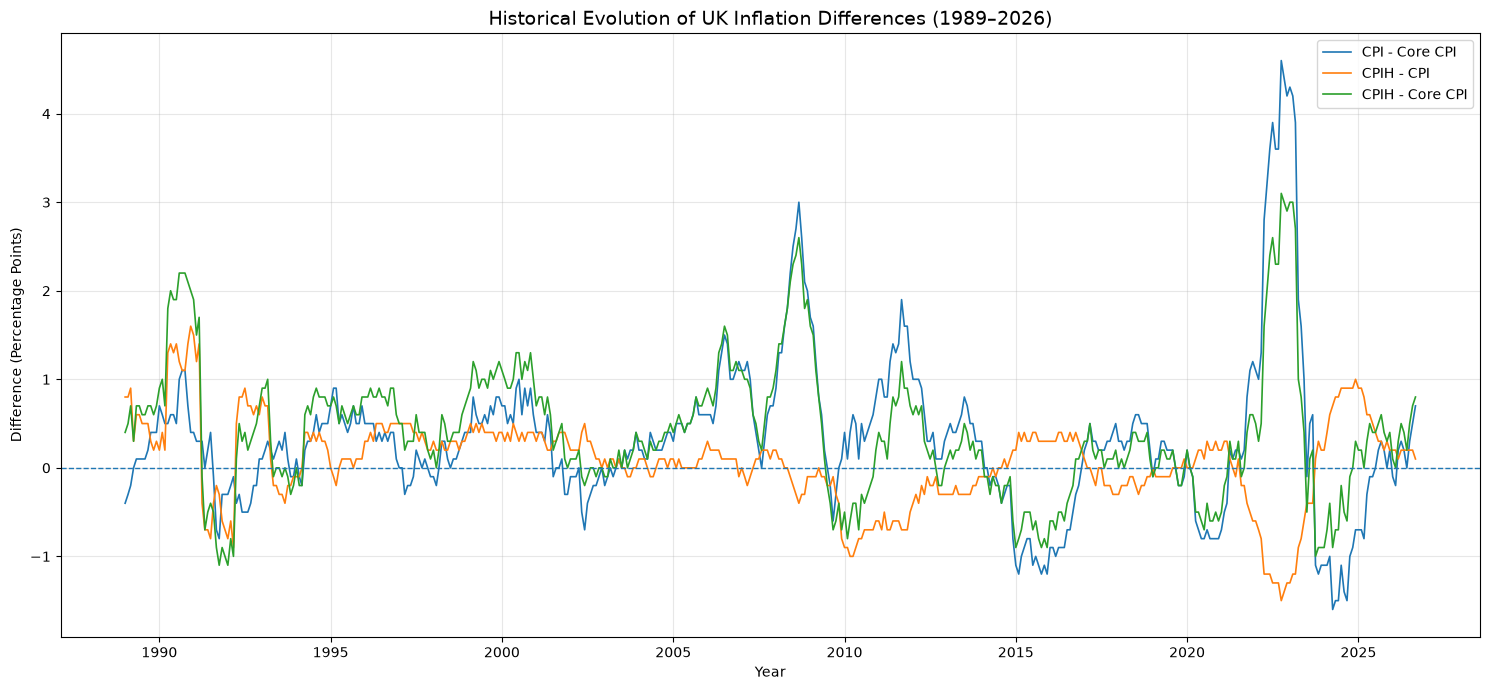

In [122]:
# Plot the historical evolution of the pairwise inflation differences.
# All values are expressed in percentage points.
# The zero reference line identifies periods when the relative difference changes sign.

plt.figure(figsize=(15, 7))

for comparison in inflation_spreads_df.columns:

    plt.plot(
        inflation_spreads_df.index,
        inflation_spreads_df[comparison],
        label=comparison,
        linewidth=1.2
    )

# Add a zero reference line to identify changes in relative inflation.
plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.title(
    "Historical Evolution of UK Inflation Differences (1989–2026)",
    fontsize=14
)

plt.xlabel("Year")
plt.ylabel("Difference (Percentage Points)")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Interpretation of Historical Inflation Differences

The pairwise differences reveal that the relationships between the three UK inflation indicators have varied considerably over time.

**1989–1992 — Early divergence**

CPIH displays higher values than CPI and Core CPI during parts of this period. The differences fluctuate and occasionally change sign.

**1993–2007 — Relatively moderate differences**

The three spreads remain predominantly close to zero, although temporary divergences are observed.

**2008–2012 — Increased divergence**

CPI minus Core CPI exhibits pronounced positive movements, particularly around 2008 and 2011. This indicates periods when headline inflation exceeded core inflation by a substantial margin.

**2013–2020 — Reduced differences**

The spreads generally become smaller, although CPI minus Core CPI records negative values during parts of 2015–2016.

**2021–2023 — Exceptional divergence**

CPI minus Core CPI increases substantially, exceeding four percentage points. At the same time, CPIH minus CPI becomes strongly negative.

This period represents the most pronounced divergence between the selected inflation indicators in the observed sample.

**2024–September 2026 — Changes in relative positioning**

The differences change direction during parts of this period. By September 2026, all three spreads are positive.

Overall, the analysis demonstrates that the relationships between CPI, Core CPI and CPIH are time-varying.

The calculated spreads are mathematically dependent transformations of the original indicators. They should not be treated as independent macroeconomic variables.

These findings are descriptive and do not establish causal relationships or predictive value.

### Rolling Correlation Analysis

This section investigates the time-varying relationships between CPI, Core CPI and CPIH.

Pearson rolling correlations are calculated using a 36-month window for the following pairs:

- CPI and Core CPI.
- CPI and CPIH.
- Core CPI and CPIH.

A rolling window is used to examine whether the relationships between the inflation indicators remain stable or change over time.

The correlation coefficient ranges from -1 to +1:

- Values close to +1 indicate a strong positive linear relationship.
- Values close to 0 indicate a weak linear relationship.
- Values close to -1 indicate a strong negative linear relationship.

A minimum of 36 valid monthly observations is required for each calculation.

The analysis is descriptive and does not establish causality or predictive relationships.

In [123]:
# Calculate 36-month rolling Pearson correlations between the inflation indicators.
# A complete 36-month window is required for each correlation estimate.
# The original monthly inflation dataset remains unchanged.

ROLLING_WINDOW = 36

inflation_rolling_corr_df = pd.DataFrame(index=inflation_monthly_df.index)

# Calculate rolling correlations for each pair of indicators.
inflation_rolling_corr_df["CPI vs Core CPI"] = (
    inflation_monthly_df["CPI"]
    .rolling(
        window=ROLLING_WINDOW,
        min_periods=ROLLING_WINDOW
    )
    .corr(inflation_monthly_df["Core CPI"])
)

inflation_rolling_corr_df["CPI vs CPIH"] = (
    inflation_monthly_df["CPI"]
    .rolling(
        window=ROLLING_WINDOW,
        min_periods=ROLLING_WINDOW
    )
    .corr(inflation_monthly_df["CPIH"])
)

inflation_rolling_corr_df["Core CPI vs CPIH"] = (
    inflation_monthly_df["Core CPI"]
    .rolling(
        window=ROLLING_WINDOW,
        min_periods=ROLLING_WINDOW
    )
    .corr(inflation_monthly_df["CPIH"])
)

# Validate the rolling correlation dataset.
print("Rolling correlation analysis completed.")

print("\nDataset shape:")
print(inflation_rolling_corr_df.shape)

print("\nFirst observations:")
display(inflation_rolling_corr_df.head(40))

print("\nLast observations:")
display(inflation_rolling_corr_df.tail())

print("\nMissing values:")
display(inflation_rolling_corr_df.isna().sum())

print("\nDescriptive statistics:")
display(
    inflation_rolling_corr_df.describe().T.round(4)
)

Rolling correlation analysis completed.

Dataset shape:
(453, 3)

First observations:


,CPI vs Core CPI,CPI vs CPIH,Core CPI vs CPIH
Date,,,
1989-01-01,NaN,NaN,NaN
1989-02-01,NaN,NaN,NaN
1989-03-01,NaN,NaN,NaN
1989-04-01,NaN,NaN,NaN
1989-05-01,NaN,NaN,NaN
1989-06-01,NaN,NaN,NaN
1989-07-01,NaN,NaN,NaN
1989-08-01,NaN,NaN,NaN
1989-09-01,NaN,NaN,NaN



Last observations:


,CPI vs Core CPI,CPI vs CPIH,Core CPI vs CPIH
Date,,,
2026-05-01,0.872274,0.982394,0.895416
2026-06-01,0.838977,0.973155,0.875452
2026-07-01,0.781967,0.963005,0.837934
2026-08-01,0.702939,0.945210,0.788137
2026-09-01,0.546314,0.897375,0.695036



Missing values:


CPI vs Core CPI     35
CPI vs CPIH         35
Core CPI vs CPIH    35
dtype: int64


Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
CPI vs Core CPI,418.0,0.8022,0.1863,0.2453,0.7269,0.8796,0.9252,0.9931
CPI vs CPIH,418.0,0.9510,0.0665,0.6557,0.9434,0.9754,0.9961,0.9999
Core CPI vs CPIH,418.0,0.7530,0.2312,-0.0627,0.6502,0.8463,0.9163,0.9875


### Historical Evolution of Rolling Correlations

This section visualises the 36-month rolling Pearson correlations between the three UK inflation indicators.

The analysis focuses on changes in the strength and direction of the relationships over time.

The three comparisons are displayed together to facilitate the identification of periods of stronger or weaker co-movement.

A correlation value close to +1 indicates a strong positive linear relationship, while values close to zero indicate a weaker linear relationship.

The visualisation helps identify whether the relationships between the inflation indicators have remained stable across different historical periods.

Rolling correlations are descriptive statistical measures. They do not establish causality or predictive relationships.

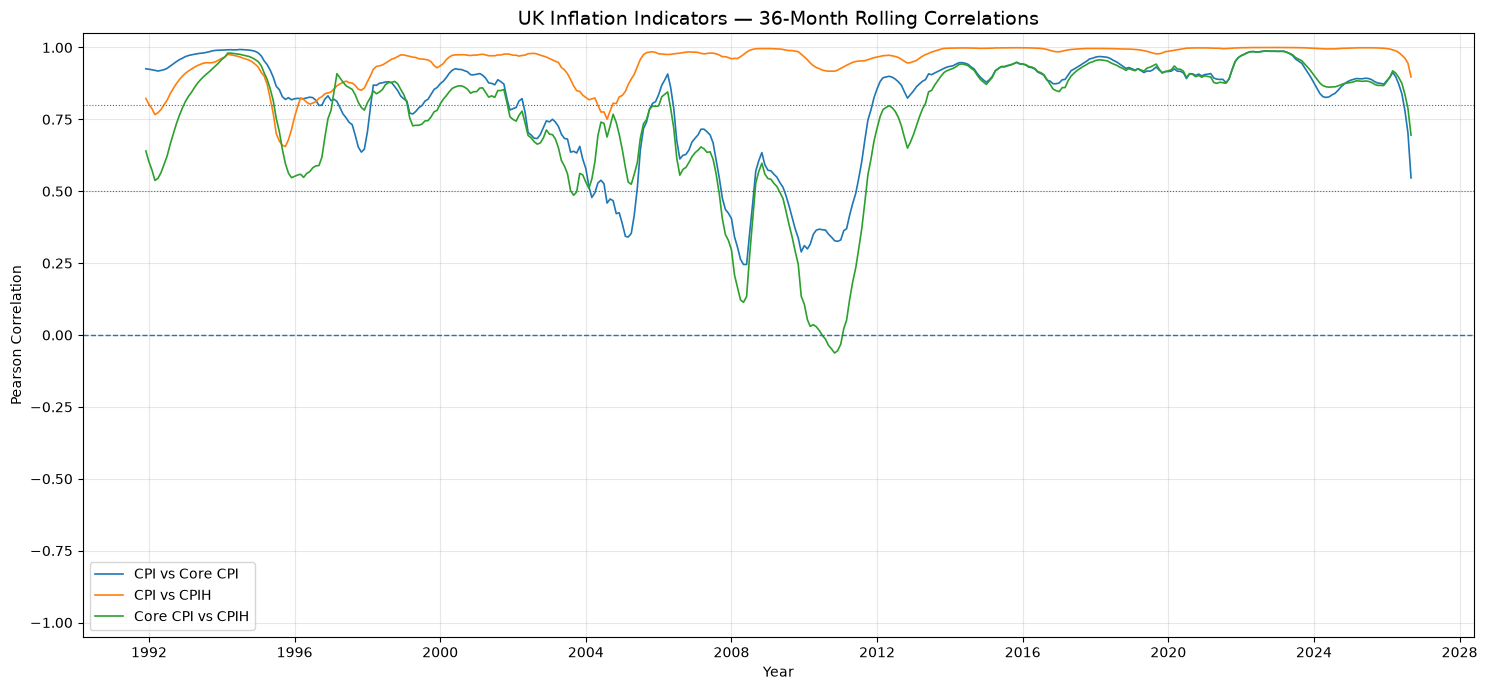

In [124]:
# Plot the historical evolution of 36-month rolling correlations.
# All three indicator pairs are displayed on the same chart.
# The horizontal reference lines help identify changes in correlation strength.

plt.figure(figsize=(15, 7))

for comparison in inflation_rolling_corr_df.columns:

    plt.plot(
        inflation_rolling_corr_df.index,
        inflation_rolling_corr_df[comparison],
        label=comparison,
        linewidth=1.2
    )

# Add reference lines for correlation interpretation.
plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.axhline(
    y=0.5,
    linestyle=":",
    linewidth=0.8
)

plt.axhline(
    y=0.8,
    linestyle=":",
    linewidth=0.8
)

plt.title(
    "UK Inflation Indicators — 36-Month Rolling Correlations",
    fontsize=14
)

plt.xlabel("Year")
plt.ylabel("Pearson Correlation")

plt.ylim(-1.05, 1.05)

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Interpretation of Rolling Correlations

The 36-month rolling correlation analysis reveals that the relationships between the three UK inflation indicators have varied over time.

**CPI vs CPIH**

This pair exhibits the strongest and most stable relationship. Rolling correlations remain predominantly above 0.90 throughout much of the sample, although temporary declines occur.

**CPI vs Core CPI**

The relationship is generally positive but considerably more variable. Several periods display substantial reductions in correlation, particularly around 2004–2005, 2008–2009 and 2024–2026.

**Core CPI vs CPIH**

This pair exhibits the greatest instability. Correlations decline substantially around 2008–2011, briefly becoming negative around 2010–2011. The relationship subsequently strengthens before weakening again towards the end of the sample.

Overall, CPI and CPIH display consistently stronger co-movement than the other indicator pairs.

The results demonstrate that relationships between inflation indicators are time-varying. Full-sample correlation statistics may therefore conceal important historical changes.

The rolling estimates use overlapping 36-month windows and should not be interpreted as independent observations. Correlation does not establish causality or predictive value.

### Quantifying Rolling Correlation Regimes

This section provides a quantitative assessment of the historical rolling correlations between the three UK inflation indicators.

The analysis includes:

- Mean and median rolling correlation.
- Minimum and maximum correlation values and their corresponding dates.
- Latest available correlation.
- Number and percentage of observations below 0.50.
- Number and percentage of observations above 0.90.

The thresholds of 0.50 and 0.90 are descriptive reference levels used to classify weaker and stronger positive linear relationships.

These classifications are analytical conventions rather than formal statistical tests.

The rolling observations are based on overlapping 36-month windows and are therefore not statistically independent.

In [125]:
# Quantify the historical regimes of the 36-month rolling correlations.
# All calculations use valid rolling correlation observations.
# The original inflation datasets remain unchanged.

correlation_regime_statistics = {}

for comparison in inflation_rolling_corr_df.columns:

    # Retain valid correlation estimates.
    correlation_series = (
        inflation_rolling_corr_df[comparison].dropna()
    )

    # Identify the dates of the minimum and maximum correlations.
    minimum_date = correlation_series.idxmin()
    maximum_date = correlation_series.idxmax()

    # Count observations within the selected descriptive thresholds.
    below_050 = (correlation_series < 0.50).sum()
    above_090 = (correlation_series > 0.90).sum()

    total_observations = len(correlation_series)

    # Calculate the descriptive statistics for this indicator pair.
    correlation_regime_statistics[comparison] = {
        "Observations": total_observations,
        "Mean Correlation": correlation_series.mean(),
        "Median Correlation": correlation_series.median(),
        "Minimum Correlation": correlation_series.min(),
        "Minimum Date": minimum_date,
        "Maximum Correlation": correlation_series.max(),
        "Maximum Date": maximum_date,
        "Latest Correlation": correlation_series.iloc[-1],
        "Observations Below 0.50": below_050,
        "Percentage Below 0.50": (
            below_050 / total_observations * 100
        ),
        "Observations Above 0.90": above_090,
        "Percentage Above 0.90": (
            above_090 / total_observations * 100
        ),
    }

# Convert the results into a structured DataFrame.
correlation_regime_df = pd.DataFrame(
    correlation_regime_statistics
).T

# Display the quantitative regime analysis.
display(
    correlation_regime_df.round(4)
)

,Observations,Mean Correlation,Median Correlation,Minimum Correlation,Minimum Date,Maximum Correlation,Maximum Date,Latest Correlation,Observations Below 0.50,Percentage Below 0.50,Observations Above 0.90,Percentage Above 0.90
CPI vs Core CPI,418,0.802207,0.879635,0.245254,2008-06-01 00:00:00,0.99307,1994-07-01 00:00:00,0.546314,47,11.244019,163,38.995215
CPI vs CPIH,418,0.950996,0.975415,0.655712,1995-10-01 00:00:00,0.999916,2022-11-01 00:00:00,0.897375,0,0.0,349,83.492823
Core CPI vs CPIH,418,0.752969,0.846334,-0.062716,2010-11-01 00:00:00,0.987476,2022-09-01 00:00:00,0.695036,43,10.287081,122,29.186603


### Interpretation of Quantified Correlation Regimes

The quantitative analysis confirms substantial differences in the historical relationships between the three UK inflation indicators.

**CPI vs CPIH**

This pair exhibits the strongest and most stable relationship, with a mean correlation of 0.9510 and a median of 0.9754.

No rolling correlation observation falls below 0.50, while 83.49% of observations exceed 0.90.

This suggests substantial statistical overlap between the two indicators, although it does not establish that they contain identical economic information.

**CPI vs Core CPI**

The mean correlation is 0.8022, with 47 observations below 0.50, representing 11.24% of valid rolling estimates.

The minimum correlation is 0.2453, recorded in June 2008.

The latest correlation, 0.5463, is below the historical mean.

**Core CPI vs CPIH**

This pair has the lowest mean correlation, at 0.7530.

Its minimum correlation is -0.0627, recorded in November 2010. A total of 43 observations, or 10.29%, fall below 0.50.

The latest correlation is 0.6950, also below its historical mean.

**Recent correlation comparison**

All three latest correlations are below their respective full-sample means, particularly CPI versus Core CPI.

This observation warrants monitoring but does not, by itself, establish a structural change.

**Overall conclusions**

The analysis indicates that CPI and CPIH have a consistently strong statistical relationship, while the relationships involving Core CPI are more variable.

The findings suggest potential informational redundancy between CPI and CPIH. This hypothesis requires further investigation before any feature-selection decision.

The rolling estimates are based on overlapping 36-month windows and are not statistically independent observations.

These results are descriptive and do not establish causality or predictive value.

In [126]:
# Identify existing Gilt-related DataFrames in the current notebook.

[name for name, obj in globals().items()
 if "gilt" in name.lower() and isinstance(obj, pd.DataFrame)]

['gilt_yields',
 'gilt_yield_statistics',
 'gilt_descriptive_stats',
 'gilt_curve_df',
 'gilt_annual_volatility']

In [127]:
# Display the existing Gilt yield dataset structure.

print("Dataset shape:", gilt_yields.shape)
print("\nColumns:")
print(gilt_yields.columns.tolist())

print("\nDate range:")
print(gilt_yields.index.min(), "to", gilt_yields.index.max())

print("\nFirst observations:")
display(gilt_yields.head())

Dataset shape: (12480, 2)

Columns:
['Gilt 2-Year (%)', 'Gilt 10-Year (%)']

Date range:
1979-01-01 00:00:00 to 2026-10-30 00:00:00

First observations:


,Gilt 2-Year (%),Gilt 10-Year (%)
Date,,
1979-01-01,NaN,NaN
1979-01-02,11.959974,12.622968
1979-01-03,11.987385,12.660829
1979-01-04,11.941209,12.635555
1979-01-05,11.885243,12.665215


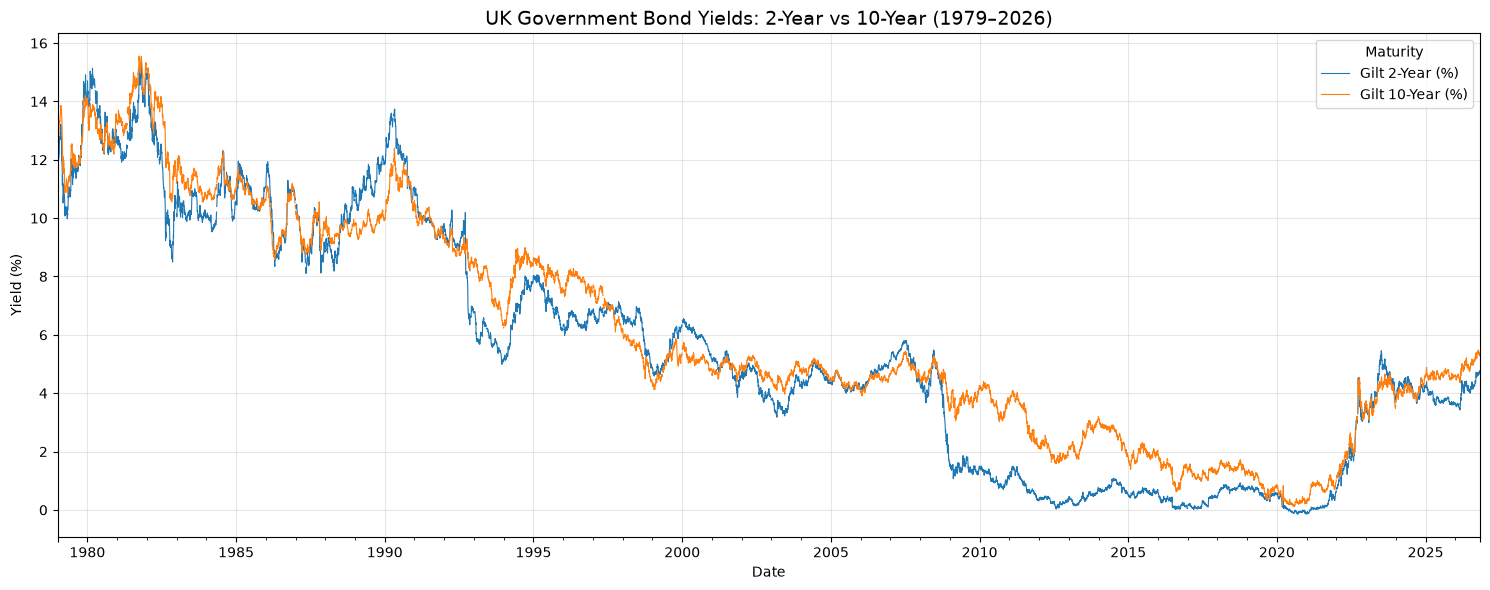

In [128]:
# Plot the historical evolution of UK Gilt yields.
# Compare the 2-year and 10-year maturities over the full available period.

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(15, 6))

gilt_yields.plot(
    ax=ax,
    linewidth=0.8
)

ax.set_title(
    "UK Government Bond Yields: 2-Year vs 10-Year (1979–2026)",
    fontsize=14
)
ax.set_xlabel("Date")
ax.set_ylabel("Yield (%)")
ax.legend(title="Maturity")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [129]:
# Calculate descriptive statistics for UK Gilt yields.
# The analysis covers the full available historical sample.

gilt_descriptive_stats = gilt_yields.describe().T

gilt_descriptive_stats["Skewness"] = gilt_yields.skew()
gilt_descriptive_stats["Excess Kurtosis"] = gilt_yields.kurtosis()

display(
    gilt_descriptive_stats.round(4)
)

,count,mean,std,min,25%,50%,75%,max,Skewness,Excess Kurtosis
Gilt 2-Year (%),12090.0,5.5408,4.1133,-0.1420,1.2970,4.9007,9.2650,15.4901,0.3394,-0.9794
Gilt 10-Year (%),12090.0,6.0849,3.7662,0.1114,3.5002,4.9009,9.3873,15.5571,0.4419,-0.8424


In [130]:
# Calculate the UK Gilt 10-Year minus 2-Year yield spread.
# Only dates with valid observations for both maturities are retained.

gilt_curve_df = gilt_yields.dropna(
    subset=["Gilt 2-Year (%)", "Gilt 10-Year (%)"]
).copy()

gilt_curve_df["10Y-2Y Spread (pp)"] = (
    gilt_curve_df["Gilt 10-Year (%)"]
    - gilt_curve_df["Gilt 2-Year (%)"]
)

spread = gilt_curve_df["10Y-2Y Spread (pp)"]

print("Aligned observations:", len(gilt_curve_df))
print("\nYield curve classification:")

print(f"Positive spread: {(spread > 0).sum():,} "
      f"({(spread > 0).mean() * 100:.2f}%)")

print(f"Negative spread: {(spread < 0).sum():,} "
      f"({(spread < 0).mean() * 100:.2f}%)")

print(f"Approximately flat (|spread| <= 0.10 pp): "
      f"{(spread.abs() <= 0.10).sum():,} "
      f"({(spread.abs() <= 0.10).mean() * 100:.2f}%)")

Aligned observations: 12090

Yield curve classification:
Positive spread: 8,664 (71.66%)
Negative spread: 3,426 (28.34%)
Approximately flat (|spread| <= 0.10 pp): 1,140 (9.43%)


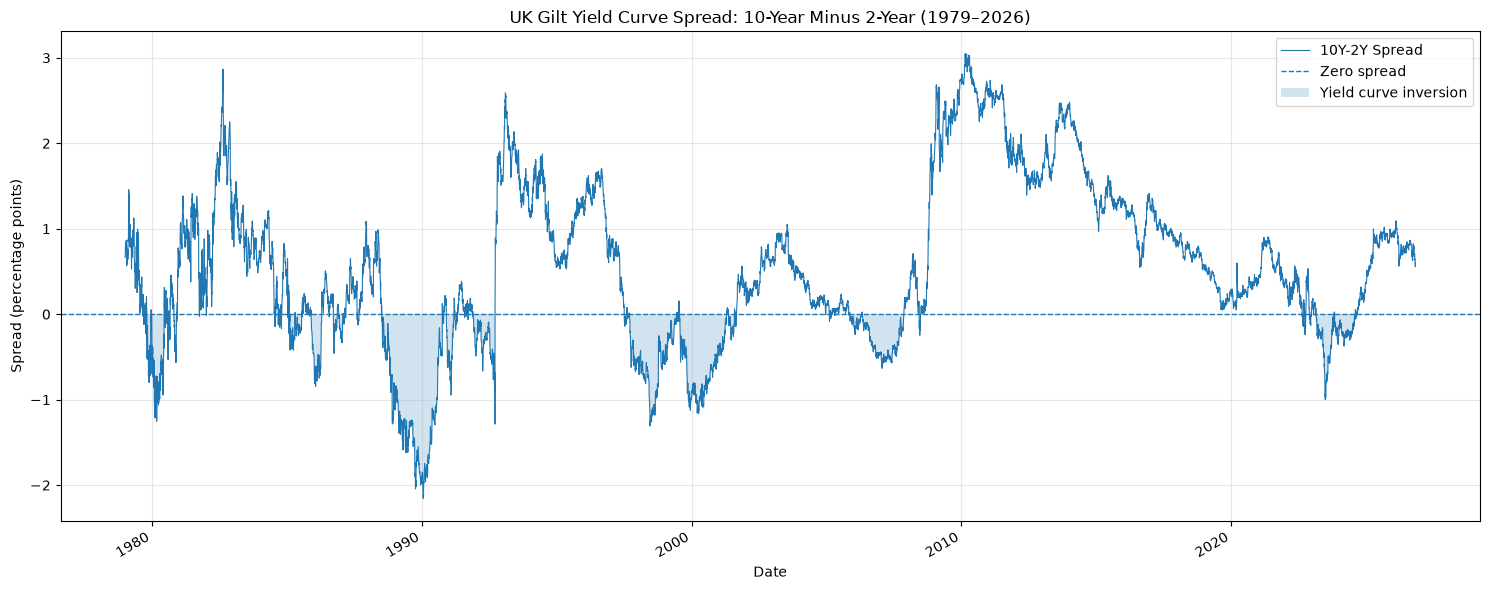

In [131]:
# Plot the historical evolution of the UK Gilt yield curve spread.
# Negative values indicate an inverted yield curve.

fig, ax = plt.subplots(figsize=(15, 6))

gilt_curve_df["10Y-2Y Spread (pp)"].plot(
    ax=ax,
    linewidth=0.8,
    label="10Y-2Y Spread"
)

ax.axhline(
    y=0,
    linestyle="--",
    linewidth=1,
    label="Zero spread"
)

ax.fill_between(
    gilt_curve_df.index,
    gilt_curve_df["10Y-2Y Spread (pp)"],
    0,
    where=gilt_curve_df["10Y-2Y Spread (pp)"] < 0,
    alpha=0.2,
    label="Yield curve inversion"
)

ax.set_title(
    "UK Gilt Yield Curve Spread: 10-Year Minus 2-Year (1979–2026)"
)
ax.set_xlabel("Date")
ax.set_ylabel("Spread (percentage points)")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [132]:
# Identify consecutive UK Gilt yield curve inversion episodes.
# An inversion occurs when the 10Y-2Y spread is negative.

inversion_mask = gilt_curve_df["10Y-2Y Spread (pp)"] < 0

episode_id = (
    inversion_mask.ne(inversion_mask.shift())
    .cumsum()
)

inversion_episodes = (
    gilt_curve_df.loc[inversion_mask]
    .assign(Episode=episode_id[inversion_mask])
    .groupby("Episode")
    .agg(
        Start_Date=("10Y-2Y Spread (pp)", lambda x: x.index.min()),
        End_Date=("10Y-2Y Spread (pp)", lambda x: x.index.max()),
        Observations=("10Y-2Y Spread (pp)", "count"),
        Minimum_Spread=("10Y-2Y Spread (pp)", "min")
    )
)

inversion_episodes["Calendar_Days"] = (
    inversion_episodes["End_Date"]
    - inversion_episodes["Start_Date"]
).dt.days + 1

display(inversion_episodes.round(3))

/tmp/ipykernel_63064/504486404.py:28: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(inversion_episodes.round(3))


,Start_Date,End_Date,Observations,Minimum_Spread,Calendar_Days
Episode,,,,,
2,1979-08-31,1979-08-31,1,-0.022,1
4,1979-09-12,1979-09-20,7,-0.121,9
6,1979-10-02,1979-10-02,1,-0.028,1
8,1979-10-09,1979-10-15,5,-0.232,7
10,1979-10-24,1979-12-18,40,-0.799,56
...,...,...,...,...,...
172,2023-02-23,2023-10-19,165,-0.999,239
174,2023-10-24,2023-10-25,2,-0.015,2
176,2023-10-31,2024-08-02,192,-0.373,277


In [133]:
# Summarise the duration and intensity of yield curve inversion episodes.

duration_summary = inversion_episodes["Calendar_Days"].describe()

print("Inversion episode duration statistics:")
display(duration_summary.to_frame("Calendar Days").round(2))

print("\nTen longest inversion episodes:")

display(
    inversion_episodes
    .sort_values("Calendar_Days", ascending=False)
    .head(10)
)

Inversion episode duration statistics:


,Calendar Days
count,90.00
mean,54.58
std,144.99
min,1.00
25%,1.00
50%,4.50
75%,18.75
max,819.00



Ten longest inversion episodes:


,Start_Date,End_Date,Observations,Minimum_Spread,Calendar_Days
Episode,,,,,
84,1988-07-08,1990-10-04,568,-2.157290,819
126,1999-07-21,2001-04-18,441,-1.163154,638
116,1997-09-11,1999-06-09,440,-1.308587,637
154,2006-05-02,2007-11-13,391,-0.634046,561
108,1991-11-26,1992-09-16,204,-1.286016,296
176,2023-10-31,2024-08-02,192,-0.373147,277
172,2023-02-23,2023-10-19,165,-0.999154,239
12,1979-12-27,1980-06-12,116,-1.252687,169
152,2005-11-15,2006-04-20,108,-0.239900,157


In [134]:
# Classify yield curve inversion episodes by calendar duration.

duration_bins = [0, 7, 30, 90, 365, float("inf")]

duration_labels = [
    "Up to 7 days",
    "8–30 days",
    "31–90 days",
    "91–365 days",
    "Over 365 days"
]

inversion_episodes["Duration_Category"] = pd.cut(
    inversion_episodes["Calendar_Days"],
    bins=duration_bins,
    labels=duration_labels
)

duration_distribution = (
    inversion_episodes["Duration_Category"]
    .value_counts(sort=False)
    .to_frame("Number of Episodes")
)

duration_distribution["Percentage"] = (
    duration_distribution["Number of Episodes"]
    / len(inversion_episodes) * 100
)

display(duration_distribution.round(2))

,Number of Episodes,Percentage
Duration_Category,,
Up to 7 days,52,57.78
8–30 days,19,21.11
31–90 days,8,8.89
91–365 days,7,7.78
Over 365 days,4,4.44


In [135]:
# Calculate 60-observation rolling volatility of the UK Gilt yield spread.
# The standard deviation measures the variability of the 10Y-2Y spread.

gilt_curve_df["Spread_Rolling_Volatility_60D"] = (
    gilt_curve_df["10Y-2Y Spread (pp)"]
    .rolling(window=60)
    .std()
)

display(
    gilt_curve_df["Spread_Rolling_Volatility_60D"]
    .describe()
    .to_frame("60-Observation Rolling Volatility")
    .round(4)
)

,60-Observation Rolling Volatility
count,12031.0000
mean,0.1365
std,0.1011
min,0.0216
25%,0.0680
50%,0.1092
75%,0.1733
max,1.0364


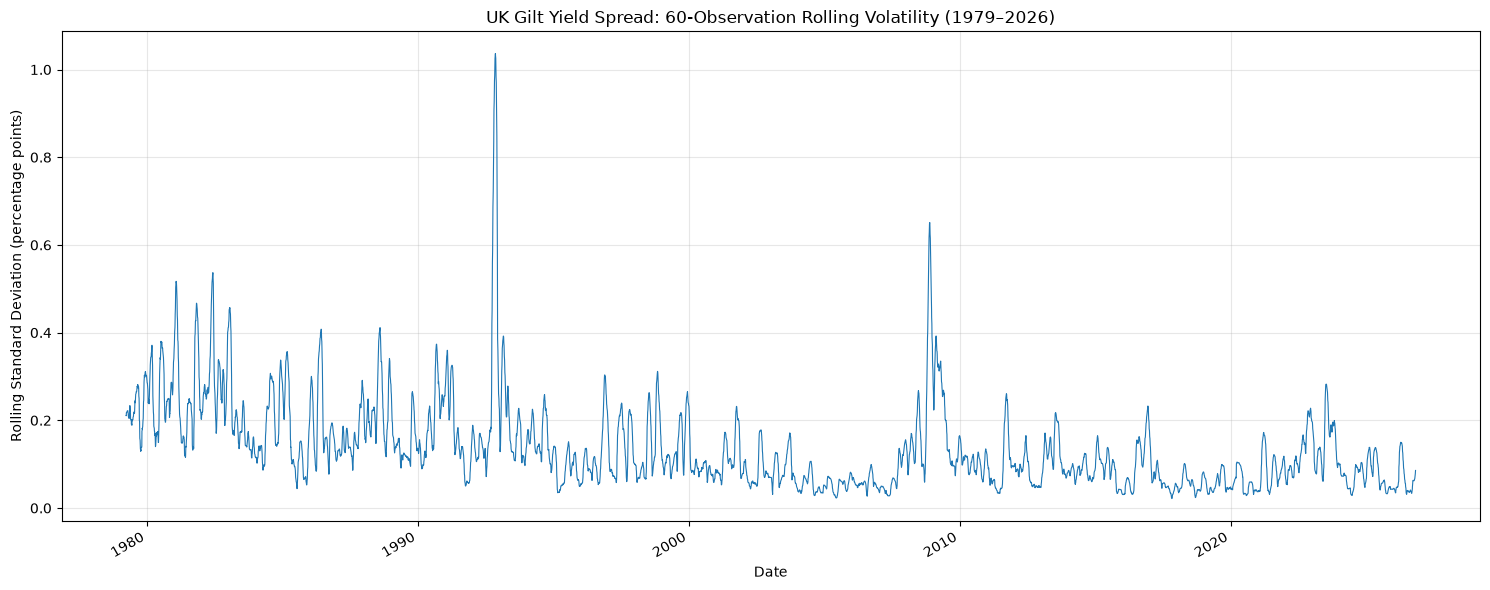

In [136]:
# Plot the historical 60-observation rolling volatility of the Gilt yield spread.

fig, ax = plt.subplots(figsize=(15, 6))

gilt_curve_df["Spread_Rolling_Volatility_60D"].plot(
    ax=ax,
    linewidth=0.8
)

ax.set_title(
    "UK Gilt Yield Spread: 60-Observation Rolling Volatility (1979–2026)"
)
ax.set_xlabel("Date")
ax.set_ylabel("Rolling Standard Deviation (percentage points)")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [137]:
# Compare rolling spread volatility during inverted and non-inverted yield curve periods.
import numpy as np

volatility_comparison = (
    gilt_curve_df
    .assign(
        Curve_Regime=lambda df: np.where(
            df["10Y-2Y Spread (pp)"] < 0,
            "Inverted",
            "Non-Inverted"
        )
    )
    .groupby("Curve_Regime")["Spread_Rolling_Volatility_60D"]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

display(volatility_comparison.round(4))

,count,mean,median,std,min,max
Curve_Regime,,,,,,
Inverted,3426,0.1441,0.1199,0.0836,0.0270,0.4114
Non-Inverted,8605,0.1334,0.1040,0.1071,0.0216,1.0364


In [138]:
# Calculate annual volatility of the UK Gilt yield curve spread.
# Annual standard deviation is calculated from daily spread observations.

gilt_annual_volatility = (
    gilt_curve_df["10Y-2Y Spread (pp)"]
    .resample("YE")
    .std()
    .to_frame("Annual Spread Volatility")
)

display(
    gilt_annual_volatility
    .sort_values("Annual Spread Volatility", ascending=False)
    .head(15)
    .round(4)
)

,Annual Spread Volatility
Date,
1992-12-31,0.8755
1990-12-31,0.7152
1982-12-31,0.6572
1988-12-31,0.6252
2008-12-31,0.6084
1979-12-31,0.5111
1997-12-31,0.5052
1980-12-31,0.4823
1984-12-31,0.3893


## Government Bond Yields — Consolidated EDA Findings

### 1. Research Scope

This analysis examined the historical evolution of UK government bond yields using the Bank of England's nominal Gilt yield curve data.

The analysis focused on two maturities:

- 2-Year Gilt yield.
- 10-Year Gilt yield.

The available dataset covers the period from January 1979 to October 2026, with 12,090 valid paired observations.

The analysis was exploratory and aimed to understand historical yield behaviour, yield curve dynamics, inversion episodes and spread volatility. No forecasting models, trading signals or causal relationships were investigated.

### 2. Historical Yield Behaviour

The historical series showed a substantial long-term decline in UK Gilt yields from the elevated levels observed during the late 1970s and early 1980s.

Both maturities experienced broadly declining yields over subsequent decades, reaching historically low levels around 2020–2021.

A substantial increase occurred from 2022 onwards, followed by a period of higher yields and continued fluctuations through October 2026.

Across the full sample:

| Statistic | 2-Year Gilt | 10-Year Gilt |
|---|---:|---:|
| Mean | 5.5408% | 6.0849% |
| Median | 4.9007% | 4.9009% |
| Standard deviation | 4.1133 | 3.7662 |
| Minimum | -0.1420% | 0.1114% |
| Maximum | 15.4901% | 15.5571% |
| Skewness | 0.3394 | 0.4419 |
| Excess kurtosis | -0.9794 | -0.8424 |

The 10-Year yield had a higher historical mean, while the 2-Year yield exhibited greater overall dispersion.

These statistics aggregate several distinct economic and monetary regimes and should not be interpreted as representative of current market conditions.

### 3. Yield Curve Spread Analysis

The yield curve spread was calculated as:

**10Y–2Y Spread = 10-Year Gilt Yield − 2-Year Gilt Yield**

The historical classification was:

| Yield Curve Regime | Observations | Percentage |
|---|---:|---:|
| Positive spread | 8,664 | 71.66% |
| Negative spread | 3,426 | 28.34% |
| Approximately flat (±0.10 percentage points) | 1,140 | 9.43% |

The positive and negative categories are based on the sign of the spread. The approximately flat category overlaps with these two categories and must not be added to them.

The yield curve exhibited a positive slope during most observations, although periods of inversion represented a substantial proportion of the historical sample.

### 4. Yield Curve Inversion Episodes

A total of 90 consecutive inversion episodes were identified.

The duration analysis produced the following results:

| Statistic | Calendar Days |
|---|---:|
| Mean | 54.58 |
| Median | 4.50 |
| Standard deviation | 144.99 |
| Minimum | 1 |
| Maximum | 819 |

The distribution of inversion episodes was:

| Duration | Episodes | Percentage |
|---|---:|---:|
| Up to 7 days | 52 | 57.78% |
| 8–30 days | 19 | 21.11% |
| 31–90 days | 8 | 8.89% |
| 91–365 days | 7 | 7.78% |
| Over 365 days | 4 | 4.44% |

Most identified inversion episodes were relatively short, with 78.89% lasting no longer than 30 calendar days.

However, a small number of episodes persisted for substantially longer periods.

The longest identified episode extended from July 1988 to October 1990, lasting 819 calendar days and reaching a minimum spread of approximately -2.16 percentage points.

Recent prolonged inversion episodes were also observed during 2023–2024.

**Methodological limitation:** Episode duration represents the calendar interval between the first and last available negative observations. It does not establish that the spread remained continuously negative on every intervening calendar day.

### 5. Spread Volatility Analysis

A rolling standard deviation based on 60 observations was calculated to examine changes in spread volatility.

| Statistic | 60-Observation Rolling Volatility |
|---|---:|
| Mean | 0.1365 |
| Median | 0.1092 |
| Standard deviation | 0.1011 |
| Minimum | 0.0216 |
| Maximum | 1.0364 |

The historical analysis identified substantial variation in spread volatility.

Notable periods included the early 1980s, 1992–1993 and 2008–2009.

Annual spread volatility also highlighted 1992 as the most volatile year in the reported ranking, with a standard deviation of 0.8755 percentage points.

Other particularly volatile years included 1990, 1982, 1988 and 2008.

### 6. Volatility by Yield Curve Regime

Rolling volatility was compared between inverted and non-inverted yield curve observations.

| Statistic | Inverted | Non-Inverted |
|---|---:|---:|
| Observations | 3,426 | 8,605 |
| Mean volatility | 0.1441 | 0.1334 |
| Median volatility | 0.1199 | 0.1040 |
| Standard deviation | 0.0836 | 0.1071 |
| Minimum | 0.0270 | 0.0216 |
| Maximum | 0.4114 | 1.0364 |

The average and median rolling volatility were higher during inverted yield curve observations.

However, the highest observed volatility occurred during non-inverted periods.

This comparison is descriptive only. Rolling estimates use overlapping observations and are not statistically independent. The results do not establish a causal relationship between yield curve inversion and spread volatility.

### 7. Key Research Findings

The exploratory analysis supports the following findings:

1. UK Gilt yields experienced a substantial long-term decline before the sharp increase observed from 2022 onwards.
2. The 10-Year yield had a higher historical average than the 2-Year yield.
3. The yield curve had a positive slope in approximately 71.66% of valid observations.
4. Inverted yield curve observations represented approximately 28.34% of the sample.
5. Most identified inversion episodes were short, although several prolonged episodes occurred.
6. Spread volatility varied considerably across historical periods.
7. The highest annual spread volatility in the reported ranking occurred in 1992.
8. Average rolling spread volatility was slightly higher during inverted yield curve observations, but the largest volatility extremes occurred during non-inverted periods.

### 8. Economic Interpretation and Research Hypotheses

Government bond yields and the yield curve may contain information about monetary policy expectations, inflation expectations, economic conditions and financing costs.

For National Grid and other utility companies, these variables may be economically relevant through several potential mechanisms:

- Corporate borrowing and refinancing costs.
- Cost of capital and long-term investment valuation.
- Relative attractiveness of dividend-paying equities.
- Market expectations regarding future interest rates and economic conditions.

These mechanisms represent research hypotheses rather than established predictive relationships.

The individual Gilt analysis does not demonstrate that these variables improve forecasts of equity returns.

### 9. Limitations

The following limitations must be retained when interpreting subsequent research:

- The historical sample combines different monetary and economic regimes.
- Descriptive statistics may conceal substantial regime-dependent behaviour.
- Rolling volatility estimates are overlapping and therefore dependent.
- Inversion episode durations are based on available observations rather than continuous calendar-day measurements.
- Historical yield observations have previously been classified as `PIT_UNVALIDATED` during Phase 3.
- Historical observation dates must not be treated as publication or information-availability timestamps.
- The analysis does not establish causal relationships or predictive value.
- Data licensing eligibility remains separate from point-in-time eligibility.

### 10. Implications for Subsequent Multi-Asset Analysis

The 2-Year and 10-Year Gilt yields and the 10Y–2Y spread will remain candidate macroeconomic variables for subsequent multi-asset research.

Their potential relevance to NG.L, SSE.L and SVT.L must be investigated through appropriately aligned observations, point-in-time controls and subsequent comparative analysis.

No variable should be retained as a model feature solely because it has an economically plausible interpretation.

Its incremental contribution must be evaluated against appropriate price-only baselines and through rigorous out-of-sample validation.

### 11. EDA Conclusion

The individual exploratory analysis of UK Government Bond Yields is considered complete.

The findings provide a historical description of UK Gilt yield behaviour, yield curve inversions and spread volatility.

No forecasting, feature selection, strategy development or trading conclusions have been made at this stage.

## 4. Economic Growth — UK GDP

### 4.1 Research Objective and Questions

This section examines UK economic growth using the Office for National Statistics (ONS) Quarterly National Accounts (QNA).

The analysis distinguishes between:
- **Real GDP level:** output measured using chained volume measures (CVM), seasonally adjusted, in £ million.
- **Quarter-on-quarter real GDP growth:** the percentage change in seasonally adjusted real GDP relative to the preceding quarter.
- **Year-on-year real GDP growth:** the percentage change relative to the corresponding period one year earlier.
- **GDP deflator growth:** the annual change in the price deflator for domestically produced output.

The analysis is descriptive. It does not test whether GDP or GDP growth predicts National Grid returns.

### 4.2 Research Questions

1. What historical coverage is available for the selected annual and quarterly GDP series?
2. How do real GDP levels and growth rates behave over the available sample?
3. How do annual real GDP growth and GDP deflator growth differ?
4. What limitations arise from frequency, missing observations and historical data availability?

### 4.3 Source and Acquisition Provenance

The source is the ONS Quarterly National Accounts acquisition already recorded in the project Raw data archive.

The acquisition inspected in this notebook is:
- Acquisition identifier: `20261105T132956Z_60b29116`
- Logical datasets: `UK_REAL_GDP` and `UK_GDP_GROWTH`
- Source file: `original_data.csv`
- Raw data is treated as immutable; all transformations below are analytical copies.

The acquisition manifest and selected series metadata are inspected in the following cells. The notebook does not modify the source file.

In [139]:
# Identify existing GDP-related DataFrames in the notebook.

[
    name for name, obj in globals().items()
    if "gdp" in name.lower()
    and isinstance(obj, pd.DataFrame)
]

['gdp_raw',
 'gdp_metadata',
 'gdp_coverage_df',
 'gdp_annual_df',
 'gdp_quarterly_df',
 'gdp_annual_ts',
 'gdp_quarterly_ts',
 'annual_gdp_stats',
 'quarterly_gdp_stats',
 'gdp_extremes_df']

In [140]:
# List existing DataFrames and their columns.
# This helps identify previously loaded GDP-related datasets.

for name, obj in globals().items():
    if isinstance(obj, pd.DataFrame):
        print(f"\n{name} | Shape: {obj.shape}")
        print("Columns:", obj.columns.tolist())


bank_rate_raw | Shape: (13104, 2)
Columns: ['DATE', 'IUDBEDR']

sonia_raw | Shape: (7496, 2)
Columns: ['DATE', 'IUDSOIA']

interest_rates | Shape: (13104, 2)
Columns: ['Bank Rate (%)', 'SONIA (%)']

interest_rate_statistics | Shape: (2, 8)
Columns: ['Observations', 'Mean (%)', 'Standard Deviation (%)', 'Minimum (%)', '25th Percentile (%)', 'Median (%)', '75th Percentile (%)', 'Maximum (%)']

raw_df | Shape: (483, 81)
Columns: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80]

extracted_df | Shape: (479, 3)
Columns: ['Date', 'Gilt 2-Year (%)', 'Gilt 10-Year (%)']

gilt_yields | Shape: (12480, 2)
Columns: ['Gilt 2-Year (%)', 'Gilt 10-Year (%)']

gilt_yield_statistics | Shape: (2, 8)
Columns: ['count', 'mean', 'std', 'min', '25

In [141]:
# List all DataFrames currently available in the notebook.

dataframes = {
    name: obj
    for name, obj in globals().items()
    if isinstance(obj, pd.DataFrame)
}

print(f"Total DataFrames found: {len(dataframes)}")

for name, df in dataframes.items():
    print(f"\n{name} | Shape: {df.shape}")
    print(f"Columns: {df.columns.tolist()}")

Total DataFrames found: 40

bank_rate_raw | Shape: (13104, 2)
Columns: ['DATE', 'IUDBEDR']

sonia_raw | Shape: (7496, 2)
Columns: ['DATE', 'IUDSOIA']

interest_rates | Shape: (13104, 2)
Columns: ['Bank Rate (%)', 'SONIA (%)']

interest_rate_statistics | Shape: (2, 8)
Columns: ['Observations', 'Mean (%)', 'Standard Deviation (%)', 'Minimum (%)', '25th Percentile (%)', 'Median (%)', '75th Percentile (%)', 'Maximum (%)']

raw_df | Shape: (483, 81)
Columns: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80]

extracted_df | Shape: (479, 3)
Columns: ['Date', 'Gilt 2-Year (%)', 'Gilt 10-Year (%)']

gilt_yields | Shape: (12480, 2)
Columns: ['Gilt 2-Year (%)', 'Gilt 10-Year (%)']

gilt_yield_statistics | Shape: (2, 8)
Columns: ['count'

In [142]:
# Search the Raw data directory for GDP-related files.
# This is a read-only inspection. No files will be modified.

from pathlib import Path

search_terms = [
    "gdp",
    "gross_domestic",
    "gross domestic",
    "economic_growth"
]

raw_files = [
    path for path in (PROJECT_ROOT / "data" / "raw").rglob("*")
    if path.is_file()
]

gdp_candidates = [
    path for path in raw_files
    if any(term in path.name.lower() for term in search_terms)
]

print(f"Total files inspected: {len(raw_files)}")
print(f"GDP-related candidates: {len(gdp_candidates)}")

for path in gdp_candidates:
    print(path.relative_to(PROJECT_ROOT))

Total files inspected: 56
GDP-related candidates: 0


In [143]:
# Inspect all files under the Raw macroeconomic data directory.
# Read-only inspection. No files will be modified.

from pathlib import Path

macro_raw_path = PROJECT_ROOT / "data" / "raw" / "macro"

macro_files = sorted(
    path for path in macro_raw_path.rglob("*")
    if path.is_file()
)

print(f"Total macroeconomic files: {len(macro_files)}\n")

for path in macro_files:
    print(f"{path.relative_to(PROJECT_ROOT)} | {path.stat().st_size:,} bytes")

Total macroeconomic files: 44

data/raw/macro/bank_of_england/uk_interest_rates/bank_rate/acquisition_20261103T162202Z_855395bd/manifest.json | 806 bytes
data/raw/macro/bank_of_england/uk_interest_rates/bank_rate/acquisition_20261103T162202Z_855395bd/original_data.csv | 231,447 bytes
data/raw/macro/bank_of_england/uk_interest_rates/bank_rate/acquisition_20261103T222444Z_01911a16/manifest.json | 733 bytes
data/raw/macro/bank_of_england/uk_interest_rates/bank_rate/acquisition_20261103T222444Z_01911a16/original_data.csv | 47 bytes
data/raw/macro/bank_of_england/uk_interest_rates/bank_rate/acquisition_20261103T222444Z_0a6ac262/manifest.json | 732 bytes
data/raw/macro/bank_of_england/uk_interest_rates/bank_rate/acquisition_20261103T222444Z_0a6ac262/original_data.csv | 47 bytes
data/raw/macro/bank_of_england/uk_interest_rates/bank_rate/acquisition_20261103T222444Z_10686ba9/manifest.json | 732 bytes
data/raw/macro/bank_of_england/uk_interest_rates/bank_rate/acquisition_20261103T222444Z_10686b

### 4.4 Series Selection and Definitions

The analysis uses the following ONS series:

| ONS code | Analytical variable | Definition | Frequency |
|---|---|---|---|
| `ABMI` | Real GDP level | GDP, chained volume measures, seasonally adjusted, £ million | Annual and quarterly |
| `IHYQ` | Real GDP quarterly growth | Quarter-on-quarter GDP growth, CVM, seasonally adjusted, % | Quarterly |
| `IHYP` | Real GDP annual growth | Year-on-year GDP growth, CVM, seasonally adjusted, % | Annual |
| `IHYS` | GDP deflator annual growth | Year-on-year GDP deflator growth, seasonally adjusted, % | Annual |

**Frequency control:** annual and quarterly observations are separated before analysis. The quarterly growth series `IHYQ` is used rather than the non-seasonally-adjusted alternative.

The GDP deflator is not interchangeable with CPI or CPIH. CPI measures prices faced by consumers; the GDP deflator reflects prices of domestically produced final output. They have different economic coverage and should not be treated as equivalent inflation measures.

In [144]:
# Inspect the existing ONS GDP acquisition.
# Read-only inspection. No Raw files will be modified.

import json
import pandas as pd
from pathlib import Path

GDP_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "macro"
    / "ons"
    / "gdp"
    / "acquisition_20261105T132956Z_60b29116"
)

manifest_path = GDP_PATH / "manifest.json"
csv_path = GDP_PATH / "original_data.csv"

# 1. Inspect acquisition manifest
with open(manifest_path, "r", encoding="utf-8") as file:
    gdp_manifest = json.load(file)

print("GDP ACQUISITION MANIFEST")
print(json.dumps(gdp_manifest, indent=4))

# 2. Load existing Raw CSV
gdp_raw = pd.read_csv(csv_path, low_memory=False)

print("\nGDP RAW DATA")
print(f"Shape: {gdp_raw.shape}")
print(f"Columns: {gdp_raw.columns.tolist()}")

# 3. Inspect first observations
display(gdp_raw.head(5))

# 4. Inspect data types and missing values
print("\nDATA TYPES")
display(gdp_raw.dtypes.to_frame("Data type"))

print("\nMISSING VALUES")
display(
    gdp_raw.isna()
    .sum()
    .to_frame("Missing values")
    .sort_values("Missing values", ascending=False)
    .head(20)
)

GDP ACQUISITION MANIFEST
{
    "manifest_version": "1.0",
    "acquisition_id": "20261105T132956Z_60b29116",
    "status": "success",
    "provider": "office_for_national_statistics",
    "source_dataset_code": "QNA",
    "dataset_ids": [
        "UK_REAL_GDP",
        "UK_GDP_GROWTH"
    ],
    "source_page": "https://www.ons.gov.uk/economy/grossdomesticproductgdp/datasets/quarterlynationalaccounts/current",
    "source_endpoint": "https://www.ons.gov.uk/file?uri=%2Feconomy%2Fgrossdomesticproductgdp%2Fdatasets%2Fquarterlynationalaccounts%2Fcurrent%2Fqna.csv",
    "retrieved_at_utc": "2026-11-05T13:29:56.154105+00:00",
    "configuration_sha256": "454b5db30f939a265852b42bffbc850baeab3d31da8a331b8cb36a3bfd99c627",
    "acquisition_scope": "one_physical_csv_shared_by_multiple_logical_datasets",
    "transformation_performed": false,
    "acquired_file": {
        "file_name": "original_data.csv",
        "format": "csv",
        "size_bytes": 2246438,
        "sha256": "8dfccc4c35c0ede47

,Title,"PP: Household final consumption expenditure, growth Q on Q","PP: NPISH final consumption expenditure, growth Q on Q","PP: General Government final consumption expenditure, growth Q on Q","PP: Gross Capital Formation, growth Q on Q","PP: Gross fixed capital formation, growth Q on Q","PP: Business investment, growth Q on Q","PP: Exports, growth Q on Q","PP: Less imports, growth Q on Q","PP: Household final consumption expenditure, growth Q on Q yr ago",...,"Deflator: Gross fixed capital formation, growth Q on Q yr ago","Deflator: Exports, growth Q on Q yr ago","Deflator: Less imports, growth Q on Q yr ago","Deflator: Household final consumption expenditure, growth annual","Deflator: NPISH final consumption expenditure, growth annual","Deflator: General Government final consumption expenditure, growth annual","Deflator: Gross Capital Formation, growth annual","Deflator: Gross fixed capital formation, growth annual","Deflator: Exports, growth annual","Deflator: Less imports, growth annual"
0,CDID,A24M,A24X,A24Y,A25I,A25J,A25M,A264,A268,A26C,...,ZZ8Y,ZZ8Z,ZZ92,ZZ93,ZZ94,ZZ95,ZZ96,ZZ97,ZZ98,ZZ99
1,PreUnit,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Unit,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Release Date,30-09-2026,30-09-2026,30-09-2026,30-09-2026,30-09-2026,30-09-2026,30-09-2026,30-09-2026,30-09-2026,...,30-09-2026,30-09-2026,30-09-2026,30-09-2026,30-09-2026,30-09-2026,30-09-2026,30-09-2026,30-09-2026,30-09-2026
4,Next release,12 November 2026,12 November 2026,12 November 2026,12 November 2026,12 November 2026,12 November 2026,12 November 2026,12 November 2026,12 November 2026,...,12 November 2026,12 November 2026,12 November 2026,12 November 2026,12 November 2026,12 November 2026,12 November 2026,12 November 2026,12 November 2026,12 November 2026



DATA TYPES


,Data type
Title,str
"PP: Household final consumption expenditure, growth Q on Q",str
"PP: NPISH final consumption expenditure, growth Q on Q",str
"PP: General Government final consumption expenditure, growth Q on Q",str
"PP: Gross Capital Formation, growth Q on Q",str
...,...
"Deflator: General Government final consumption expenditure, growth annual",str
"Deflator: Gross Capital Formation, growth annual",str
"Deflator: Gross fixed capital formation, growth annual",str
"Deflator: Exports, growth annual",str



MISSING VALUES


,Missing values
"Gross Fixed Capital Formation: Whole economy: Other buildings and structures and transfer costs: CVM SA, % chan",377
"Business investment, cont annual",377
"Revision: Business investment, growth annual",377
Gross Fixed Capital Formation: Business Investment: CP SA: % change latest year on previous year,377
"PP: Compensation of employees, growth annual",376
"Revision: GOS of corporations, growth annual",376
"Deflator: Household final consumption expenditure, growth annual",376
"Other income, cont annual",376
"GOS of corporations, cont annual",376
"Revision: Other income, growth annual",376


In [145]:
# Identify the main GDP-related series and inspect their metadata.
# Read-only analysis. The original Raw dataset remains unchanged.

gdp_keywords = [
    "gross domestic product",
    "gdp",
    "implied gdp deflator"
]

gdp_columns = [
    column
    for column in gdp_raw.columns
    if any(keyword in column.lower() for keyword in gdp_keywords)
]

print(f"GDP-related series identified: {len(gdp_columns)}")

# Display the metadata for the identified series.
gdp_metadata = gdp_raw.loc[
    0:4,
    ["Title"] + gdp_columns
].copy()

display(gdp_metadata.T)

# Inspect the first and last observations in the date column.
print("\nFIRST 15 ROW LABELS")
display(gdp_raw["Title"].head(15))

print("\nLAST 10 ROW LABELS")
display(gdp_raw["Title"].tail(10))

GDP-related series identified: 55


,0,1,2,3,4
Title,CDID,PreUnit,Unit,Release Date,Next release
"Gross Domestic Product at market prices, q-on-q1 growth: CP: NSA £m",A8L9,NaN,NaN,30-09-2026,12 November 2026
"Gross Domestic Product at market prices, q-on-q4 growth: CP: NSA £m",A8LA,NaN,NaN,30-09-2026,12 November 2026
Gross Domestic Product: chained volume measures: Seasonally adjusted £m,ABMI,£,m,30-09-2026,12 November 2026
Gross Domestic Product: Quarter on Quarter growth: CVM NSA %,BFDW,NaN,NaN,30-09-2026,12 November 2026
Gross Domestic Product: q-on-q4 growth rate CVM NSA %,BFDY,NaN,NaN,30-09-2026,12 November 2026
Gross Domestic Product at market prices: CP: NSA £m,BKTL,£,m,30-09-2026,12 November 2026
Gross Domestic Product: CVM: NSA £m,BKVT,NaN,NaN,30-09-2026,12 November 2026
Gross Domestic Product (Expenditure) current basic prices: aligned:SA £m,CAGQ,£,m,30-09-2026,12 November 2026
Gross Domestic Product (Expenditure) chained volume measure SA £m,CAGR,£,m,30-09-2026,12 November 2026



FIRST 15 ROW LABELS


0                CDID
1             PreUnit
2                Unit
3        Release Date
4        Next release
5     Important Notes
6                1946
7                1947
8                1948
9                1949
10               1950
11               1951
12               1952
13               1953
14               1954
Name: Title, dtype: str


LAST 10 ROW LABELS


398    2024 Q1
399    2024 Q2
400    2024 Q3
401    2024 Q4
402    2025 Q1
403    2025 Q2
404    2025 Q3
405    2025 Q4
406    2026 Q1
407    2026 Q2
Name: Title, dtype: str

In [146]:
# Inspect selected ONS GDP series.
# Read-only inspection. No Raw data is modified.

selected_gdp_columns = {
    "Real GDP Level": (
        "Gross Domestic Product: chained volume measures: "
        "Seasonally adjusted £m"
    ),
    "Real GDP Quarterly Growth": (
        "Gross Domestic Product: Quarter on Quarter growth: CVM SA %"
    ),
    "Real GDP Annual Growth": (
        "Gross Domestic Product: Year on Year growth: CVM SA %"
    ),
    "GDP Deflator Annual Growth": (
        "GDP Deflator: Year on Year growth: SA %"
    )
}

# Verify that all selected columns exist.
for indicator, column in selected_gdp_columns.items():
    print(f"{indicator}: {'FOUND' if column in gdp_raw.columns else 'NOT FOUND'}")

# Inspect the first observations.
print("\nFIRST OBSERVATIONS")
display(
    gdp_raw[
        ["Title"] + list(selected_gdp_columns.values())
    ].head(20)
)

# Inspect observations around the annual-to-quarterly transition.
print("\nOBSERVATIONS AROUND THE TEMPORAL TRANSITION")
display(
    gdp_raw[
        ["Title"] + list(selected_gdp_columns.values())
    ].iloc[35:55]
)

# Inspect the most recent observations.
print("\nLATEST OBSERVATIONS")
display(
    gdp_raw[
        ["Title"] + list(selected_gdp_columns.values())
    ].tail(12)
)

Real GDP Level: FOUND
Real GDP Quarterly Growth: FOUND
Real GDP Annual Growth: FOUND
GDP Deflator Annual Growth: FOUND

FIRST OBSERVATIONS


,Title,Gross Domestic Product: chained volume measures: Seasonally adjusted £m,Gross Domestic Product: Quarter on Quarter growth: CVM SA %,Gross Domestic Product: Year on Year growth: CVM SA %,GDP Deflator: Year on Year growth: SA %
0,CDID,ABMI,IHYQ,IHYP,IHYS
1,PreUnit,£,NaN,NaN,NaN
2,Unit,m,%,%,%
3,Release Date,30-09-2026,30-09-2026,30-09-2026,30-09-2026
4,Next release,12 November 2026,12 November 2026,12 November 2026,12 November 2026
5,Important Notes,NaN,NaN,NaN,NaN
6,1946,NaN,NaN,NaN,NaN
7,1947,NaN,NaN,NaN,NaN
8,1948,468350,NaN,NaN,NaN
9,1949,483721,NaN,3.3,3.1



OBSERVATIONS AROUND THE TEMPORAL TRANSITION


,Title,Gross Domestic Product: chained volume measures: Seasonally adjusted £m,Gross Domestic Product: Quarter on Quarter growth: CVM SA %,Gross Domestic Product: Year on Year growth: CVM SA %,GDP Deflator: Year on Year growth: SA %
35,1975,1050361,NaN,-1.5,26.1
36,1976,1082130,NaN,3.0,15.5
37,1977,1108829,NaN,2.5,13.9
38,1978,1155206,NaN,4.2,11.8
39,1979,1198278,NaN,3.7,14.4
40,1980,1173625,NaN,-2.1,20.1
41,1981,1167079,NaN,-0.6,12.4
42,1982,1190293,NaN,2.0,8.0
43,1983,1240111,NaN,4.2,5.5
44,1984,1267922,NaN,2.2,5.2



LATEST OBSERVATIONS


,Title,Gross Domestic Product: chained volume measures: Seasonally adjusted £m,Gross Domestic Product: Quarter on Quarter growth: CVM SA %,Gross Domestic Product: Year on Year growth: CVM SA %,GDP Deflator: Year on Year growth: SA %
396,2023 Q3,718217,-0.2,NaN,NaN
397,2023 Q4,716359,-0.3,NaN,NaN
398,2024 Q1,721604,0.7,NaN,NaN
399,2024 Q2,726081,0.6,NaN,NaN
400,2024 Q3,727325,0.2,NaN,NaN
401,2024 Q4,729940,0.4,NaN,NaN
402,2025 Q1,734321,0.6,NaN,NaN
403,2025 Q2,734373,0.0,NaN,NaN
404,2025 Q3,735710,0.2,NaN,NaN
405,2025 Q4,735791,0.0,NaN,NaN


In [147]:
# Inspect the annual-to-quarterly transition in the ONS GDP dataset.
# Read-only inspection. No Raw data is modified.

display(
    gdp_raw[
        ["Title"] + list(selected_gdp_columns.values())
    ].iloc[48:62]
)

,Title,Gross Domestic Product: chained volume measures: Seasonally adjusted £m,Gross Domestic Product: Quarter on Quarter growth: CVM SA %,Gross Domestic Product: Year on Year growth: CVM SA %,GDP Deflator: Year on Year growth: SA %
48,1988,1513089,NaN,5.4,6.1
49,1989,1549692,NaN,2.4,8.0
50,1990,1558252,NaN,0.6,8.5
51,1991,1536136,NaN,-1.4,6.7
52,1992,1540310,NaN,0.3,3.3
53,1993,1575361,NaN,2.3,3.0
54,1994,1629268,NaN,3.4,1.8
55,1995,1668497,NaN,2.4,2.6
56,1996,1712184,NaN,2.6,4.1
57,1997,1796039,NaN,4.9,0.0


### 4.5 Frequency, Coverage and Missing-Data Assessment

The source file contains annual and quarterly observations in a single wide-format extract. The analysis identifies the frequency from the ONS period labels and evaluates coverage separately.

The selected series do not all have the same effective historical coverage:
- Annual real GDP level (`ABMI`): 78 valid observations, from 1948 to 2025.
- Annual real GDP growth (`IHYP`): 77 valid observations, from 1949 to 2025.
- Annual GDP deflator growth (`IHYS`): 77 valid observations, from 1949 to 2025.
- Quarterly real GDP level (`ABMI`): 286 valid observations, from 1955 Q1 to 2026 Q2.
- Quarterly real GDP growth (`IHYQ`): 285 valid observations, from 1955 Q2 to 2026 Q2.

These coverage figures describe the selected extract and should not be interpreted as evidence that the series were available to a market participant at each historical observation date. The project’s Phase 3 assessment classified the historical GDP data as `PIT_UNVALIDATED`; publication-time eligibility has not been established.

In [148]:
# Identify the first and last annual and quarterly observations.
# Read-only inspection. No Raw data is modified.

titles = gdp_raw["Title"].astype(str).str.strip()

quarterly_mask = titles.str.contains(
    r"^\d{4}\s+Q[1-4]$",
    regex=True
)

annual_mask = titles.str.fullmatch(r"\d{4}")

print("ANNUAL OBSERVATIONS")
print("First:", titles[annual_mask].iloc[0])
print("Last:", titles[annual_mask].iloc[-1])
print("Count:", annual_mask.sum())

print("\nQUARTERLY OBSERVATIONS")
print("First:", titles[quarterly_mask].iloc[0])
print("Last:", titles[quarterly_mask].iloc[-1])
print("Count:", quarterly_mask.sum())

print("\nTRANSITION")
transition_position = quarterly_mask[quarterly_mask].index[0]

display(
    gdp_raw.iloc[
        transition_position - 3:transition_position + 5
    ][["Title"] + list(selected_gdp_columns.values())]
)

ANNUAL OBSERVATIONS
First: 1946
Last: 2025
Count: 80

QUARTERLY OBSERVATIONS
First: 1946 Q1
Last: 2026 Q2
Count: 322

TRANSITION


,Title,Gross Domestic Product: chained volume measures: Seasonally adjusted £m,Gross Domestic Product: Quarter on Quarter growth: CVM SA %,Gross Domestic Product: Year on Year growth: CVM SA %,GDP Deflator: Year on Year growth: SA %
83,2023,2872948,NaN,0.4,6.3
84,2024,2904950,NaN,1.1,3.8
85,2025,2940195,NaN,1.2,3.6
86,1946 Q1,NaN,NaN,NaN,NaN
87,1946 Q2,NaN,NaN,NaN,NaN
88,1946 Q3,NaN,NaN,NaN,NaN
89,1946 Q4,NaN,NaN,NaN,NaN
90,1947 Q1,NaN,NaN,NaN,NaN


In [149]:
# Assess the effective coverage of selected GDP indicators.
# Read-only inspection. No Raw data is modified.

import pandas as pd

gdp_columns = list(selected_gdp_columns.values())

titles = gdp_raw["Title"].astype(str).str.strip()

annual_mask = titles.str.fullmatch(r"\d{4}")
quarterly_mask = titles.str.fullmatch(r"\d{4}\s+Q[1-4]")

coverage = []

for frequency, mask in [
    ("Annual", annual_mask),
    ("Quarterly", quarterly_mask)
]:
    subset = gdp_raw.loc[mask, gdp_columns]

    for column in gdp_columns:
        valid = subset[column].notna()

        coverage.append({
            "Frequency": frequency,
            "Indicator": column,
            "Total Observations": len(subset),
            "Valid Observations": valid.sum(),
            "Missing Observations": subset[column].isna().sum(),
            "First Valid Observation": (
                gdp_raw.loc[mask & gdp_raw[column].notna(), "Title"].iloc[0]
                if valid.any() else None
            ),
            "Last Valid Observation": (
                gdp_raw.loc[mask & gdp_raw[column].notna(), "Title"].iloc[-1]
                if valid.any() else None
            )
        })

gdp_coverage_df = pd.DataFrame(coverage)

display(gdp_coverage_df)

,Frequency,Indicator,Total Observations,Valid Observations,Missing Observations,First Valid Observation,Last Valid Observation
0,Annual,Gross Domestic Product: chained volume measure...,80,78,2,1948,2025
1,Annual,Gross Domestic Product: Quarter on Quarter gro...,80,0,80,NaN,NaN
2,Annual,Gross Domestic Product: Year on Year growth: C...,80,77,3,1949,2025
3,Annual,GDP Deflator: Year on Year growth: SA %,80,77,3,1949,2025
4,Quarterly,Gross Domestic Product: chained volume measure...,322,286,36,1955 Q1,2026 Q2
5,Quarterly,Gross Domestic Product: Quarter on Quarter gro...,322,285,37,1955 Q2,2026 Q2
6,Quarterly,Gross Domestic Product: Year on Year growth: C...,322,0,322,NaN,NaN
7,Quarterly,GDP Deflator: Year on Year growth: SA %,322,0,322,NaN,NaN


In [150]:
# Inspect missing observation patterns in the selected GDP series.
# Read-only inspection. No Raw data is modified.

gdp_missing_analysis = {}

for frequency, mask in [
    ("Annual", annual_mask),
    ("Quarterly", quarterly_mask)
]:

    subset = gdp_raw.loc[
        mask,
        ["Title"] + gdp_columns
    ].copy()

    print(f"\n{'=' * 70}")
    print(f"{frequency.upper()} GDP — MISSING OBSERVATIONS")
    print(f"{'=' * 70}")

    for column in gdp_columns:

        missing_titles = subset.loc[
            subset[column].isna(),
            "Title"
        ].tolist()

        gdp_missing_analysis[
            f"{frequency}_{column}"
        ] = missing_titles

        print(f"\nIndicator: {column}")
        print(f"Missing count: {len(missing_titles)}")
        print(f"Missing periods: {missing_titles}")


ANNUAL GDP — MISSING OBSERVATIONS

Indicator: Gross Domestic Product: chained volume measures: Seasonally adjusted £m
Missing count: 2
Missing periods: ['1946', '1947']

Indicator: Gross Domestic Product: Quarter on Quarter growth: CVM SA %
Missing count: 80
Missing periods: ['1946', '1947', '1948', '1949', '1950', '1951', '1952', '1953', '1954', '1955', '1956', '1957', '1958', '1959', '1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']

Indicator: Gross Domestic Product: Year on Year growth: CVM SA %
Missing count: 3

### 4.6 Frequency-Aware Data Preparation

Annual and quarterly observations are converted into separate time-series datasets. The Raw source remains unchanged.

The annual dataset retains the annual level and annual growth indicators. The quarterly dataset retains the quarterly level and quarter-on-quarter growth indicator.

**Important:** annual GDP level observations and quarterly GDP level observations are different frequency representations. Their numerical values must not be compared directly as if they were observations on the same scale or period basis.

In [151]:
# Prepare separate annual and quarterly GDP datasets for EDA.
# Raw source data remains unchanged.

gdp_annual_df = gdp_raw.loc[
    annual_mask,
    ["Title"] + list(selected_gdp_columns.values())
].copy()

gdp_quarterly_df = gdp_raw.loc[
    quarterly_mask,
    ["Title"] + list(selected_gdp_columns.values())
].copy()

# Retain indicators relevant to each frequency.
annual_columns = [
    "Gross Domestic Product: chained volume measures: Seasonally adjusted £m",
    "Gross Domestic Product: Year on Year growth: CVM SA %",
    "GDP Deflator: Year on Year growth: SA %"
]

quarterly_columns = [
    "Gross Domestic Product: chained volume measures: Seasonally adjusted £m",
    "Gross Domestic Product: Quarter on Quarter growth: CVM SA %"
]

# Select frequency-compatible indicators.
gdp_annual_df = gdp_annual_df[
    ["Title"] + annual_columns
].copy()

gdp_quarterly_df = gdp_quarterly_df[
    ["Title"] + quarterly_columns
].copy()

# Retain valid observations without filling missing values.
gdp_annual_df = gdp_annual_df.dropna(
    subset=annual_columns,
    how="all"
)

gdp_quarterly_df = gdp_quarterly_df.dropna(
    subset=quarterly_columns,
    how="all"
)

print("ANNUAL GDP DATASET")
print("Shape:", gdp_annual_df.shape)
display(gdp_annual_df.head())
display(gdp_annual_df.tail())

print("\nQUARTERLY GDP DATASET")
print("Shape:", gdp_quarterly_df.shape)
display(gdp_quarterly_df.head())
display(gdp_quarterly_df.tail())

ANNUAL GDP DATASET
Shape: (78, 4)


,Title,Gross Domestic Product: chained volume measures: Seasonally adjusted £m,Gross Domestic Product: Year on Year growth: CVM SA %,GDP Deflator: Year on Year growth: SA %
8,1948,468350,NaN,NaN
9,1949,483721,3.3,3.1
10,1950,499756,3.3,1.3
11,1951,518371,3.7,8.2
12,1952,526105,1.5,7.0


,Title,Gross Domestic Product: chained volume measures: Seasonally adjusted £m,Gross Domestic Product: Year on Year growth: CVM SA %,GDP Deflator: Year on Year growth: SA %
81,2021,2723513,8.5,0.8
82,2022,2860259,5.0,5.7
83,2023,2872948,0.4,6.3
84,2024,2904950,1.1,3.8
85,2025,2940195,1.2,3.6



QUARTERLY GDP DATASET
Shape: (286, 3)


,Title,Gross Domestic Product: chained volume measures: Seasonally adjusted £m,Gross Domestic Product: Quarter on Quarter growth: CVM SA %
122,1955 Q1,149440,NaN
123,1955 Q2,149645,0.1
124,1955 Q3,152285,1.8
125,1955 Q4,151421,-0.6
126,1956 Q1,153195,1.2


,Title,Gross Domestic Product: chained volume measures: Seasonally adjusted £m,Gross Domestic Product: Quarter on Quarter growth: CVM SA %
403,2025 Q2,734373,0.0
404,2025 Q3,735710,0.2
405,2025 Q4,735791,0.0
406,2026 Q1,740509,0.6
407,2026 Q2,744453,0.5


In [152]:
# Convert GDP analytical datasets into frequency-aware time series.
# Raw source data remains unchanged.

# ---------------------------------------------------------
# Annual GDP
# ---------------------------------------------------------

gdp_annual_ts = gdp_annual_df.copy()

gdp_annual_ts["Period"] = pd.PeriodIndex(
    gdp_annual_ts["Title"].astype(str),
    freq="Y"
)

for column in annual_columns:
    gdp_annual_ts[column] = pd.to_numeric(
        gdp_annual_ts[column],
        errors="coerce"
    )

gdp_annual_ts = (
    gdp_annual_ts
    .drop(columns="Title")
    .set_index("Period")
    .sort_index()
)

# ---------------------------------------------------------
# Quarterly GDP
# ---------------------------------------------------------

gdp_quarterly_ts = gdp_quarterly_df.copy()

# Explicitly parse quarterly labels using the year and quarter.
quarterly_periods = (
    gdp_quarterly_ts["Title"]
    .astype(str)
    .str.extract(r"^(\d{4})\s+Q([1-4])$")
)

gdp_quarterly_ts["Period"] = pd.PeriodIndex(
    quarterly_periods[0] + "Q" + quarterly_periods[1],
    freq="Q-DEC"
)

for column in quarterly_columns:
    gdp_quarterly_ts[column] = pd.to_numeric(
        gdp_quarterly_ts[column],
        errors="coerce"
    )

gdp_quarterly_ts = (
    gdp_quarterly_ts
    .drop(columns="Title")
    .set_index("Period")
    .sort_index()
)

# ---------------------------------------------------------
# Validation
# ---------------------------------------------------------

print("ANNUAL GDP TIME SERIES")
print("Shape:", gdp_annual_ts.shape)
print("Index type:", type(gdp_annual_ts.index))
print("Index frequency:", gdp_annual_ts.index.freq)
print("Data types:")
print(gdp_annual_ts.dtypes)

display(gdp_annual_ts.head())
display(gdp_annual_ts.tail())

print("\nQUARTERLY GDP TIME SERIES")
print("Shape:", gdp_quarterly_ts.shape)
print("Index type:", type(gdp_quarterly_ts.index))
print("Index frequency:", gdp_quarterly_ts.index.freq)
print("Data types:")
print(gdp_quarterly_ts.dtypes)

display(gdp_quarterly_ts.head())
display(gdp_quarterly_ts.tail())

ANNUAL GDP TIME SERIES
Shape: (78, 3)
Index type: <class 'pandas.PeriodIndex'>
Index frequency: <YearEnd: month=12>
Data types:
Gross Domestic Product: chained volume measures: Seasonally adjusted £m      int64
Gross Domestic Product: Year on Year growth: CVM SA %                      float64
GDP Deflator: Year on Year growth: SA %                                    float64
dtype: object


,Gross Domestic Product: chained volume measures: Seasonally adjusted £m,Gross Domestic Product: Year on Year growth: CVM SA %,GDP Deflator: Year on Year growth: SA %
Period,,,
1948,468350,NaN,NaN
1949,483721,3.3,3.1
1950,499756,3.3,1.3
1951,518371,3.7,8.2
1952,526105,1.5,7.0


,Gross Domestic Product: chained volume measures: Seasonally adjusted £m,Gross Domestic Product: Year on Year growth: CVM SA %,GDP Deflator: Year on Year growth: SA %
Period,,,
2021,2723513,8.5,0.8
2022,2860259,5.0,5.7
2023,2872948,0.4,6.3
2024,2904950,1.1,3.8
2025,2940195,1.2,3.6



QUARTERLY GDP TIME SERIES
Shape: (286, 2)
Index type: <class 'pandas.PeriodIndex'>
Index frequency: <QuarterEnd: startingMonth=12>
Data types:
Gross Domestic Product: chained volume measures: Seasonally adjusted £m      int64
Gross Domestic Product: Quarter on Quarter growth: CVM SA %                float64
dtype: object


,Gross Domestic Product: chained volume measures: Seasonally adjusted £m,Gross Domestic Product: Quarter on Quarter growth: CVM SA %
Period,,
1955Q1,149440,NaN
1955Q2,149645,0.1
1955Q3,152285,1.8
1955Q4,151421,-0.6
1956Q1,153195,1.2


,Gross Domestic Product: chained volume measures: Seasonally adjusted £m,Gross Domestic Product: Quarter on Quarter growth: CVM SA %
Period,,
2025Q2,734373,0.0
2025Q3,735710,0.2
2025Q4,735791,0.0
2026Q1,740509,0.6
2026Q2,744453,0.5


### 4.7 Descriptive Statistics

Descriptive statistics are calculated independently for annual and quarterly series. The level variables are expressed in £ million; growth and deflator variables are expressed in percentages.

The descriptive statistics are intended to characterise central tendency, dispersion and distribution shape. They do not establish causal relationships or forecasting value.

In [153]:
# Descriptive statistical analysis of UK GDP indicators.
# Annual and quarterly frequencies are analysed independently.
# Raw source data remains unchanged.

# ---------------------------------------------------------
# Annual GDP — Descriptive Statistics
# ---------------------------------------------------------

annual_gdp_stats = gdp_annual_ts.describe().T

annual_gdp_stats["skewness"] = gdp_annual_ts.skew()
annual_gdp_stats["excess_kurtosis"] = gdp_annual_ts.kurtosis()

print("=" * 80)
print("ANNUAL GDP — DESCRIPTIVE STATISTICS")
print("=" * 80)

display(annual_gdp_stats.round(4))


# ---------------------------------------------------------
# Quarterly GDP — Descriptive Statistics
# ---------------------------------------------------------

quarterly_gdp_stats = gdp_quarterly_ts.describe().T

quarterly_gdp_stats["skewness"] = gdp_quarterly_ts.skew()
quarterly_gdp_stats["excess_kurtosis"] = gdp_quarterly_ts.kurtosis()

print("\n" + "=" * 80)
print("QUARTERLY GDP — DESCRIPTIVE STATISTICS")
print("=" * 80)

display(quarterly_gdp_stats.round(4))

ANNUAL GDP — DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max,skewness,excess_kurtosis
Gross Domestic Product: chained volume measures: Seasonally adjusted £m,78.0,1.536288e+06,761984.8845,468350.0,872497.25,1398061.0,2263988.25,2940195.0,0.3197,-1.2273
Gross Domestic Product: Year on Year growth: CVM SA %,77.0,2.444200e+00,2.5430,-10.0,1.60,2.5,3.70,8.5,-1.7108,7.2549
GDP Deflator: Year on Year growth: SA %,77.0,5.084400e+00,4.6974,0.0,1.90,3.6,6.60,26.1,2.1196,5.5913



QUARTERLY GDP — DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max,skewness,excess_kurtosis
Gross Domestic Product: chained volume measures: Seasonally adjusted £m,286.0,411483.6783,181810.9141,149440.0,260575.0,385230.0,578786.75,744453.0,0.2630,-1.2653
Gross Domestic Product: Quarter on Quarter growth: CVM SA %,285.0,0.5839,1.8656,-19.9,0.2,0.6,1.00,16.9,-2.1518,71.2761


### 4.8 Extreme Growth Observations

The following analysis identifies the largest and smallest observed growth values in the selected annual and quarterly series.

Extreme observations require economic and statistical context. In particular, large quarterly movements around exceptional economic disruptions can materially affect skewness and kurtosis. They should not be removed automatically: any treatment would require a documented economic rationale and a separate robustness analysis.

In [154]:
# Identify extreme observations in GDP growth indicators.
# Descriptive inspection only. No data is modified.

extreme_series = {
    "Annual Real GDP Growth": (
        gdp_annual_ts[
            "Gross Domestic Product: Year on Year growth: CVM SA %"
        ]
    ),
    "Annual GDP Deflator Growth": (
        gdp_annual_ts[
            "GDP Deflator: Year on Year growth: SA %"
        ]
    ),
    "Quarterly Real GDP Growth": (
        gdp_quarterly_ts[
            "Gross Domestic Product: Quarter on Quarter growth: CVM SA %"
        ]
    )
}

extreme_results = []

for indicator, series in extreme_series.items():

    valid_series = series.dropna()

    extreme_results.append({
        "Indicator": indicator,
        "Minimum": valid_series.min(),
        "Minimum Period": str(valid_series.idxmin()),
        "Maximum": valid_series.max(),
        "Maximum Period": str(valid_series.idxmax())
    })

gdp_extremes_df = pd.DataFrame(extreme_results)

display(gdp_extremes_df)

,Indicator,Minimum,Minimum Period,Maximum,Maximum Period
0,Annual Real GDP Growth,-10.0,2020,8.5,2021
1,Annual GDP Deflator Growth,0.0,1997,26.1,1975
2,Quarterly Real GDP Growth,-19.9,2020Q2,16.9,2020Q3


### 4.9 Historical Visualisation

The next figures visualise:
- the annual real GDP level;
- annual real GDP growth alongside GDP deflator growth; and
- quarterly real GDP growth.

The figures are descriptive and retain the frequency of the underlying ONS series. No interpolation between annual and quarterly observations is performed.

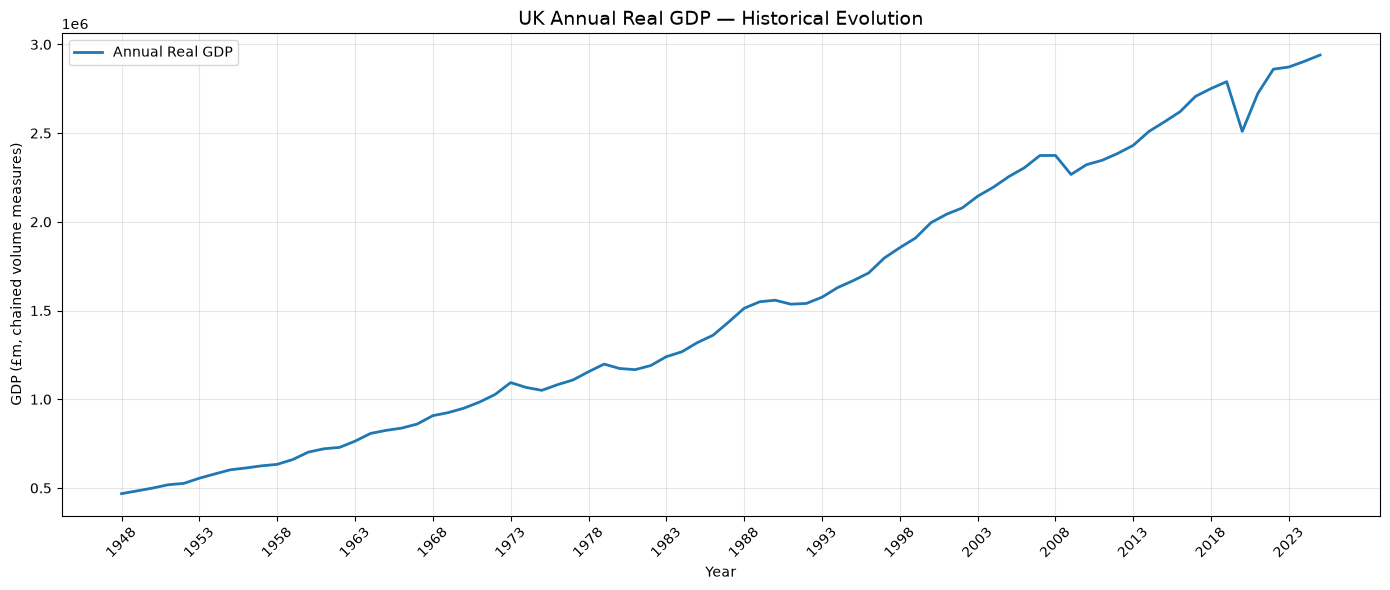

In [155]:
# Plot the historical evolution of UK annual real GDP.
# Source: ONS Quarterly National Accounts.
# Values are seasonally adjusted chained volume measures (£m).

import matplotlib.pyplot as plt

annual_gdp_level = gdp_annual_ts[
    "Gross Domestic Product: chained volume measures: Seasonally adjusted £m"
]

plt.figure(figsize=(14, 6))

plt.plot(
    annual_gdp_level.index.astype(str),
    annual_gdp_level.values,
    linewidth=2,
    label="Annual Real GDP"
)

plt.title(
    "UK Annual Real GDP — Historical Evolution",
    fontsize=14
)

plt.xlabel("Year")
plt.ylabel("GDP (£m, chained volume measures)")

plt.xticks(
    range(0, len(annual_gdp_level), 5),
    rotation=45
)

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

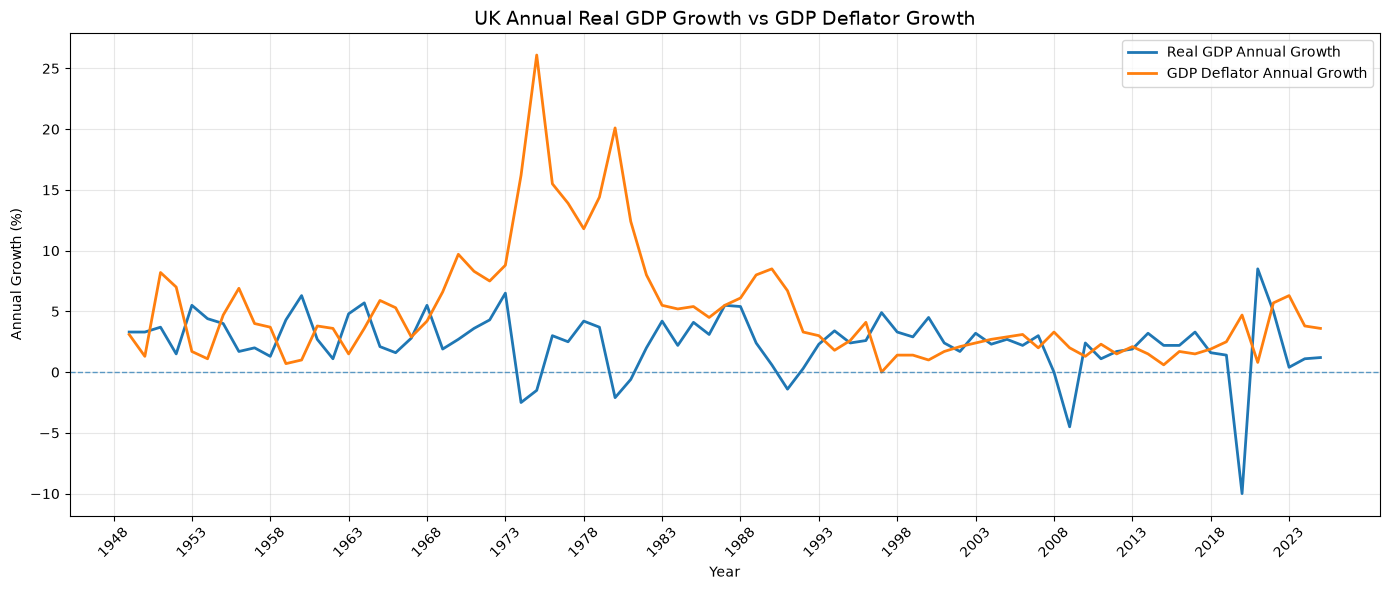

In [156]:
# Plot annual real GDP growth and GDP deflator growth.
# Both indicators are expressed as year-on-year percentages.

annual_growth = gdp_annual_ts[
    "Gross Domestic Product: Year on Year growth: CVM SA %"
]

annual_deflator = gdp_annual_ts[
    "GDP Deflator: Year on Year growth: SA %"
]

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    annual_growth.index.astype(str),
    annual_growth.values,
    label="Real GDP Annual Growth",
    linewidth=2
)

ax.plot(
    annual_deflator.index.astype(str),
    annual_deflator.values,
    label="GDP Deflator Annual Growth",
    linewidth=2
)

ax.axhline(0, linewidth=1, linestyle="--", alpha=0.7)

ax.set_title(
    "UK Annual Real GDP Growth vs GDP Deflator Growth",
    fontsize=14
)

ax.set_xlabel("Year")
ax.set_ylabel("Annual Growth (%)")

ax.set_xticks(
    range(0, len(annual_growth), 5)
)

ax.set_xticklabels(
    annual_growth.index.astype(str)[::5],
    rotation=45
)

ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

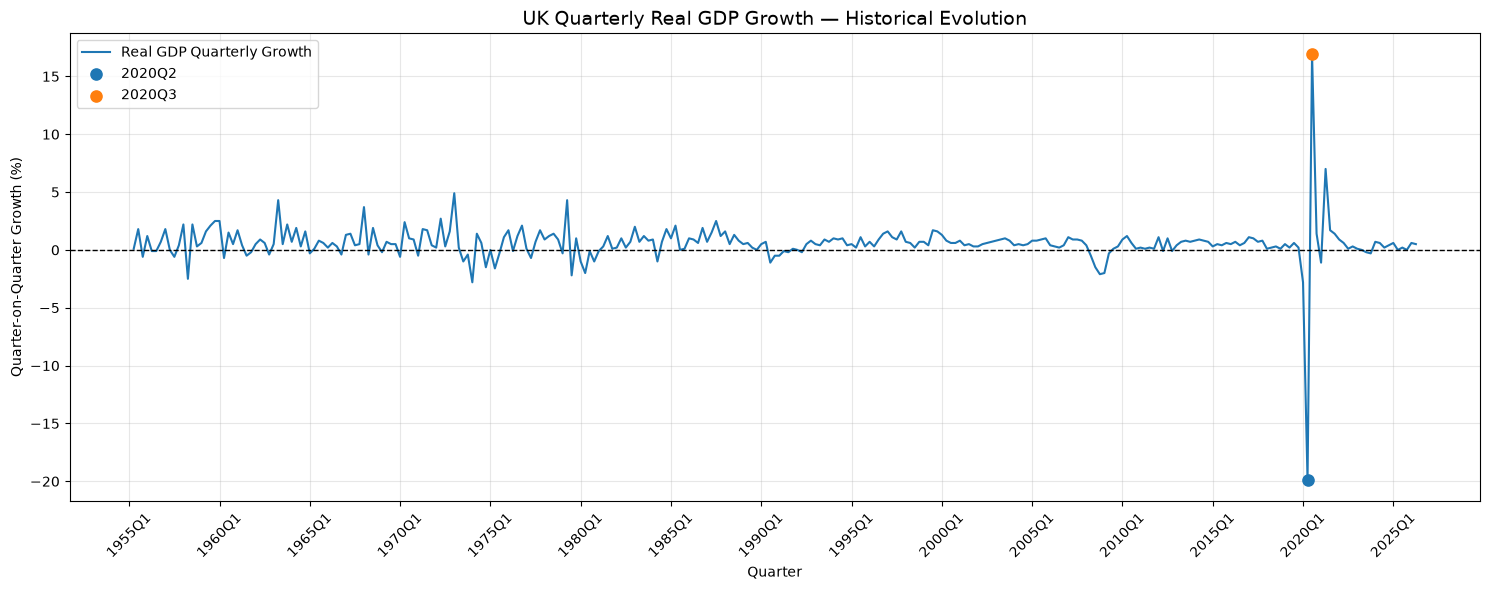

In [157]:
# Plot quarterly UK real GDP growth.
# Source: ONS Quarterly National Accounts.
# Seasonally adjusted quarter-on-quarter growth rates.

quarterly_growth = gdp_quarterly_ts[
    "Gross Domestic Product: Quarter on Quarter growth: CVM SA %"
]

fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(
    quarterly_growth.index.astype(str),
    quarterly_growth.values,
    linewidth=1.5,
    label="Real GDP Quarterly Growth"
)

ax.axhline(
    0,
    color="black",
    linewidth=1,
    linestyle="--"
)

# Highlight the exceptional COVID-19 observations.
for period in ["2020Q2", "2020Q3"]:
    if pd.Period(period, freq="Q-DEC") in quarterly_growth.index:
        value = quarterly_growth.loc[pd.Period(period, freq="Q-DEC")]

        ax.scatter(
            period,
            value,
            s=65,
            zorder=5,
            label=period
        )

ax.set_title(
    "UK Quarterly Real GDP Growth — Historical Evolution",
    fontsize=14
)

ax.set_xlabel("Quarter")
ax.set_ylabel("Quarter-on-Quarter Growth (%)")

tick_positions = range(0, len(quarterly_growth), 20)

ax.set_xticks(list(tick_positions))
ax.set_xticklabels(
    quarterly_growth.index.astype(str)[::20],
    rotation=45
)

ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

## 5. Integrated Macroeconomic Findings

### 5.1 Interest Rates and Monetary Conditions

The Bank Rate and SONIA provide complementary descriptions of UK monetary conditions: the Bank Rate represents the policy rate, while SONIA is an overnight wholesale funding benchmark. Their historical relationship and changes in monetary regimes are relevant context for analysing the financing environment of capital-intensive utilities.

These series are not interchangeable. SONIA methodology changed on 23 April 2018, which should be considered when interpreting its long historical record.

### 5.2 Government Bond Yields and the Yield Curve

The Gilt analysis examines nominal 2-year and 10-year yields and the 10Y–2Y spread. The historical sample contains 12,090 paired observations. The spread was positive in 8,664 observations (71.66%) and negative in 3,426 observations (28.34%).

The analysis identifies 90 consecutive inversion episodes. Their duration is measured between the first and last available negative observations in each episode; it does not establish that the spread remained negative on every calendar day between those observations.

The yield curve and its volatility may provide context for interest-rate expectations, refinancing conditions and the relative attractiveness of income-producing assets. These are economic hypotheses, not demonstrated predictive relationships with NG.L returns.

### 5.3 Inflation

The inflation analysis compares CPI, Core CPI and CPIH annual rates. Over the analysed sample, CPI and CPIH display a strong historical relationship, while correlations involving Core CPI vary more substantially across rolling windows.

The measures contain overlapping information but are not identical. CPIH includes owner-occupiers' housing costs, while Core CPI excludes selected volatile components. The observed correlations do not establish causation or incremental forecasting value.

The spreads between the inflation measures are algebraically related. In particular, CPIH minus Core CPI equals the sum of (CPIH minus CPI) and (CPI minus Core CPI); these spreads must not be treated as independent explanatory variables without accounting for this identity.

### 5.4 Economic Growth and the GDP Deflator

The ONS analysis distinguishes real output levels, real GDP growth and GDP deflator growth. Annual and quarterly series have different coverage and are analysed separately.

Quarterly real GDP growth exhibits substantial distributional extremes, including the recorded minimum of -19.9% in 2020 Q2 and maximum of 16.9% in 2020 Q3. These values materially affect distribution statistics and warrant contextual interpretation rather than automatic exclusion.

GDP deflator growth provides a broad measure of prices associated with domestically produced output. It complements, but does not replace, consumer price measures such as CPI and CPIH.

### 5.5 Implications for Subsequent Research

The analyses motivate hypotheses for later investigation, including:
- interest-rate and yield-curve conditions may be associated with financing and refinancing conditions;
- inflation may affect operating costs, regulated returns and the real value of cash flows;
- economic growth may influence electricity demand and the broader macroeconomic environment;
- macroeconomic variables may contain overlapping information and may add little incremental value once market variables are considered.

These hypotheses must be tested in later phases using correctly aligned, point-in-time eligible data, controlled baselines and out-of-sample evaluation. No macroeconomic variable is approved as a forecasting feature by this EDA alone.

## 6. Data Limitations and Research Risks

### 6.1 Historical Availability and Point-in-Time Eligibility

The Phase 3 assessment classified the historical Gilt and GDP datasets as `PIT_UNVALIDATED`. Observation dates are not equivalent to publication or market-availability timestamps. The analyses therefore describe historical observations but do not establish that each value was available to a trading decision at the corresponding date.

The same point-in-time discipline must be applied to all macroeconomic series before they can be used in predictive modelling.

### 6.2 Frequency and Calendar Alignment

The notebook contains daily or business-day financial rates, monthly inflation observations, and annual and quarterly GDP observations. Their frequencies differ. Any future integration must respect release dates, publication delays, revisions, market calendars and the timestamp at which information became available.

Forward-filling must not be applied before the relevant release or publication time.

### 6.3 Statistical Interpretation

- Correlation does not imply causation.
- Rolling correlations use overlapping windows and are not independent observations.
- Descriptive statistics can be sensitive to structural breaks and extreme observations.
- Yield-curve inversion episode durations are based on available observations, not continuous daily coverage.
- Algebraically related inflation spreads are not independent measures.
- Annual and quarterly GDP levels must not be compared directly.

### 6.4 Data Licensing

Technical availability and analytical suitability do not establish permission for commercial use or redistribution. The project’s source-licensing decisions remain in force. In particular, FRED/ALFRED data must not be used for model training without written authorisation that expressly resolves the relevant restriction.

### 6.5 Scope Boundary

This notebook is exploratory. It does not perform feature engineering, target construction, forecasting, causal inference, strategy design or backtesting. No trading decision or risk limit is derived from these descriptive analyses.

## 7. Conclusions

This notebook provides a descriptive review of UK interest rates, government bond yields, inflation indicators and economic growth using the project’s acquired datasets.

The analysis identifies meaningful historical variation in monetary conditions, the yield curve, inflation measures and real GDP. It also highlights important distinctions between indicators, frequencies and data-availability constraints.

The results support a set of economic hypotheses for later research, but they do not demonstrate that any macroeconomic series predicts National Grid returns or improves a trading strategy. Such claims require point-in-time eligible data, temporal validation, baseline comparisons and out-of-sample evidence.

The most important constraint carried forward is historical availability: the Gilt and GDP datasets remain `PIT_UNVALIDATED` under the Phase 3 assessment. This must be resolved or explicitly excluded before those observations are used in predictive experiments.

**Overall conclusion:** the macroeconomic EDA is a research foundation, not a feature approval or a trading signal.

## 8. Next Steps

1. Complete the Phase 4 multi-asset analysis in Notebook 07 using only the approved acquired datasets.
2. Review Notebooks 06, 07 and 08 together for consistent definitions, sample periods and interpretation.
3. Produce the Phase 4 consolidated report and update the project decision and risk logs.
4. Obtain explicit approval to close Phase 4 before starting the next project phase.

No feature engineering or forecasting work is initiated by this notebook.